In [1]:
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter, defaultdict
import os
import scipy.stats as stats
from scipy.special import logsumexp
import pandas as pd
import matplotlib.cm as cm
import math
import itertools
import random
from matplotlib.colors import TwoSlopeNorm, LinearSegmentedColormap
from random import random

from scipy.stats import linregress
from sklearn.linear_model import RANSACRegressor, LinearRegression
from scipy.stats import chi2_contingency, fisher_exact

import sys
sys.path.append('../src')

from visualization import (
    plot_cost_function_with_minima, 
    plot_ploidy_optimization,
    plot_ploidy_comparison,  # Add this
    print_overlap_matrix, 
    plot_overlap_matrix_figure,
    plot_uniformity_histograms_nice
)
from copy_number import (
    make_unif_dict, 
    compute_read_counts_relative_to_normal,
    compute_average_segment_counts, 
    compute_optimal_ploidy_and_profile,
    create_copy_number_matrix_fast
)

import time

In [2]:
numb = "46"
tumor = "t"+numb

In [3]:
bincounts = pd.read_csv(f"../data/{tumor}/{tumor}.bin_count_table_all_cells.txt", sep = "\t")
bincounts_no_WGS = pd.read_csv(f"../data/{tumor}/{tumor}.bincounts_without_WGS_segmentation.txt", sep="\t")
cells = pd.read_csv(f"../data/{tumor}/{tumor}.not_broken_final_list.txt", header=None)[0].values
#normal_cells = pd.read_csv(f"../data/{tumor}/normal_cells.txt", header=None, sep="\t")[0].values

In [4]:
bincounts[bincounts["chrom"]=="chr19"]

,chrom,loc.start,loc.end,abstart,abend,AAAACCAAACTTAGAGA,AAAACCAAAGTAGTTCT,AAAACCAAATCCCGTCT,AAAACCAACAAGACAAT,AAAACCAACAAGATTGG,...,TTGGACGTTTTACGAAT,TTGGGATAAACCATACG,TTTCGAGTTTTACAATA,TTTCGATGGTGCGAATC,TTTCGATTCGGCCGTTC,TTTTGGAGAATTTAAGC,TTTTGGATGAGGGTAGC,TTTTGGGTTTTACTAGA,TTTTGGTGCAGGACTTC,TTTTGGTTTAGTAGACT
106,chr19,0,8508703,2659444323,2667953026,259,100,87,230,5,...,276,8,297,301,81,101,82,3,26,71
107,chr19,9181554,23863753,2668625877,2683308076,717,253,333,421,2,...,694,139,708,527,506,219,202,131,551,266
108,chr19,24449630,30400661,2683893953,2689844984,338,50,87,77,30,...,214,42,278,150,306,122,57,136,365,110
109,chr19,30952034,37745190,2690396357,2697189513,661,123,200,222,45,...,430,76,648,291,634,291,253,185,1129,208
110,chr19,38365091,51427251,2697809414,2710871574,942,185,349,372,32,...,684,189,802,331,488,227,139,186,915,267
111,chr19,51989553,52549123,2711433876,2711993446,39,7,16,17,1,...,25,7,32,3,65,1,1,2,18,12
112,chr19,53123695,58522984,2712568018,2717967307,286,83,111,153,11,...,69,86,349,101,295,79,37,88,281,69


In [5]:
A_df = pd.read_csv(f"../data/{tumor}/{tumor}_new_population_assignments_A.txt", sep="\t")
B_df = pd.read_csv(f"../data/{tumor}/{tumor}_new_population_assignments_B.txt", sep="\t")
C_df = pd.read_csv(f"../data/{tumor}/{tumor}_new_population_assignments_C.txt", sep="\t")
D_df = pd.read_csv(f"../data/{tumor}/{tumor}_new_population_assignments_D.txt", sep="\t")
equi_df = pd.read_csv(f"../data/{tumor}/{tumor}_population_assignments_equi_bins.txt", sep="\t")
#C_df = pd.read_csv(f"../data/{tumor}/{tumor}_population_assignments_C_WGS_with_broken_cells.txt", sep="\t")

In [6]:
A_df.head()

,cell,population,normal_population
0,AAAACCAAAGTAGTTCT,A1,True
1,AAAACCAACAAGACAAT,A1,True
2,AAAATGGACCATGCACG,A1,True
3,AAAATGTGTTAAGATTA,A1,True
4,AAAGCAGACCATAATGC,A1,True


In [7]:
A_dict = {}
for cluster in A_df['population'].unique():
    print(cluster)
    cells_in_cluster = A_df[A_df['population'] == cluster]['cell'].tolist()
    A_dict[cluster] = {
        'cells': cells_in_cluster
    }


A1
A21
A221
A2221
A2222


In [8]:
B_dict = {}
for cluster in B_df['population'].unique():
    print(cluster)
    cells_in_cluster = B_df[B_df['population'] == cluster]['cell'].tolist()
    B_dict[cluster] = {
        'cells': cells_in_cluster
    }

B1
B211
B2121
B2122
B22


In [9]:
C_dict = {}
for cluster in C_df['population'].unique():
    print(cluster)
    cells_in_cluster = C_df[C_df['population'] == cluster]['cell'].tolist()
    C_dict[cluster] = {
        'cells': cells_in_cluster
    }

C11
C1211
C1212
C122
C2


In [10]:
D_dict = {}
for cluster in D_df['population'].unique():
    print(cluster)
    cells_in_cluster = D_df[D_df['population'] == cluster]['cell'].tolist()
    D_dict[cluster] = {
        'cells': cells_in_cluster
    }

D111
D1121
D1122
D12
D2


In [11]:
equi_dict = {}
for cluster in equi_df['population'].unique():
    print(cluster)
    cells_in_cluster = equi_df[equi_df['population'] == cluster]['cell'].tolist()
    equi_dict[cluster] = {
        'cells': cells_in_cluster
    }

Pop1
Pop2111
Pop2112
Pop212
Pop22


In [12]:
overlap_df = print_overlap_matrix(A_dict, equi_dict, name1="WGS bins - ", name2="equi-partitioned bins -")


Overlap Matrix (WGS bins -  rows vs equi-partitioned bins - cols):
Pop         Pop1 Pop2111 Pop2112  Pop212   Pop22
A1           261       1       0       0       1
A21            1       0       2       2     482
A221           0      19       2     163       2
A2221          0      12     177       2       3
A2222          0     230       0       0       8


In [13]:
new_order = []
for col in overlap_df.columns:
    #Find the index of the maximum value in the column
    max_index = overlap_df[col].idxmax()
    if max_index not in new_order:
        new_order.append(max_index)

for row in overlap_df.index:
    if row not in new_order:
        new_order.append(row)
new_order_dict = {k: A_dict[k] for k in new_order}
    

In [14]:
cluster_counts = bincounts[["chrom", "abstart", "abend"]].copy()
for cluster in A_dict.keys():
    cells_in_cluster = A_dict[cluster]['cells']
    cluster_counts[cluster] = bincounts[cells_in_cluster].sum(axis=1)

In [15]:
cluster_counts.to_csv(f"../data/{tumor}/{tumor}_cluster_counts_A_WGS_bins.txt", sep="\t", index=False)


Overlap Matrix (A rows vs B cols):
Pop         Pop1 Pop2111 Pop2112  Pop212   Pop22
A1           261       1       0       0       1
A21            1       0       2       2     482
A221           0      19       2     163       2
A2221          0      12     177       2       3
A2222          0     230       0       0       8


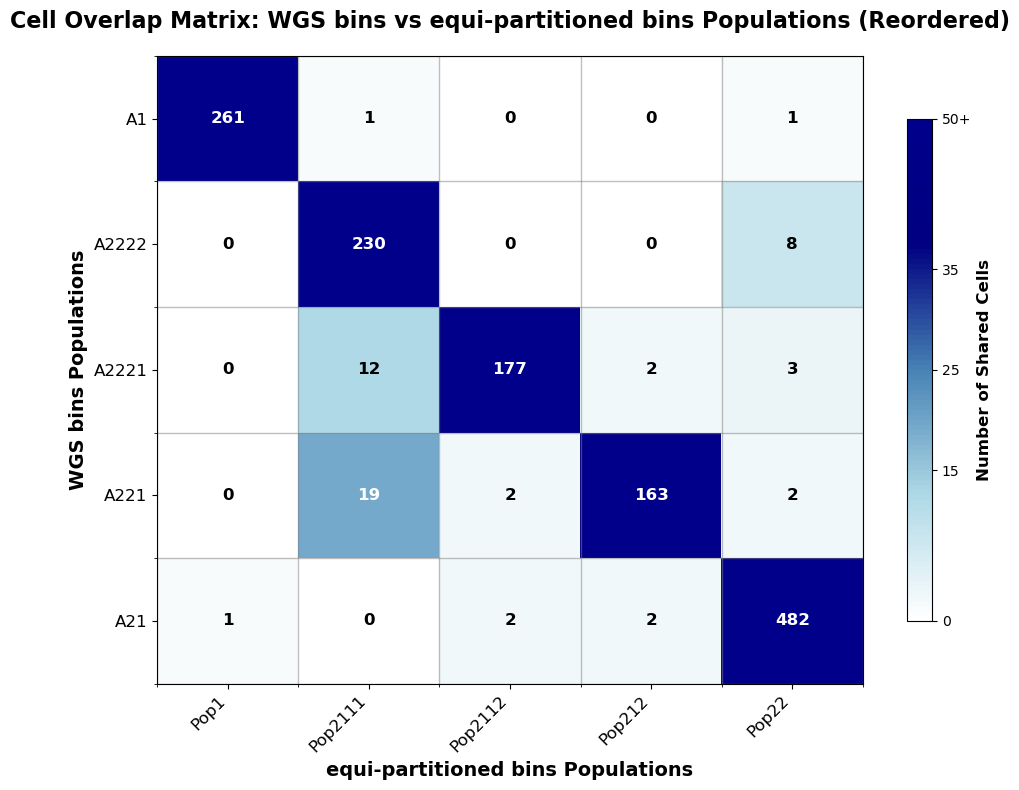

In [16]:
overlap_df = plot_overlap_matrix_figure(A_dict, equi_dict, name1="WGS bins", name2="equi-partitioned bins")


Overlap Matrix (A rows vs B cols):
Pop           B1    B211   B2121   B2122     B22
A1           263       0       0       0       0
A21            0       2       2       1     482
A221           0     179       0       6       1
A2221          0       8     185       0       1
A2222          0       3      14     221       0


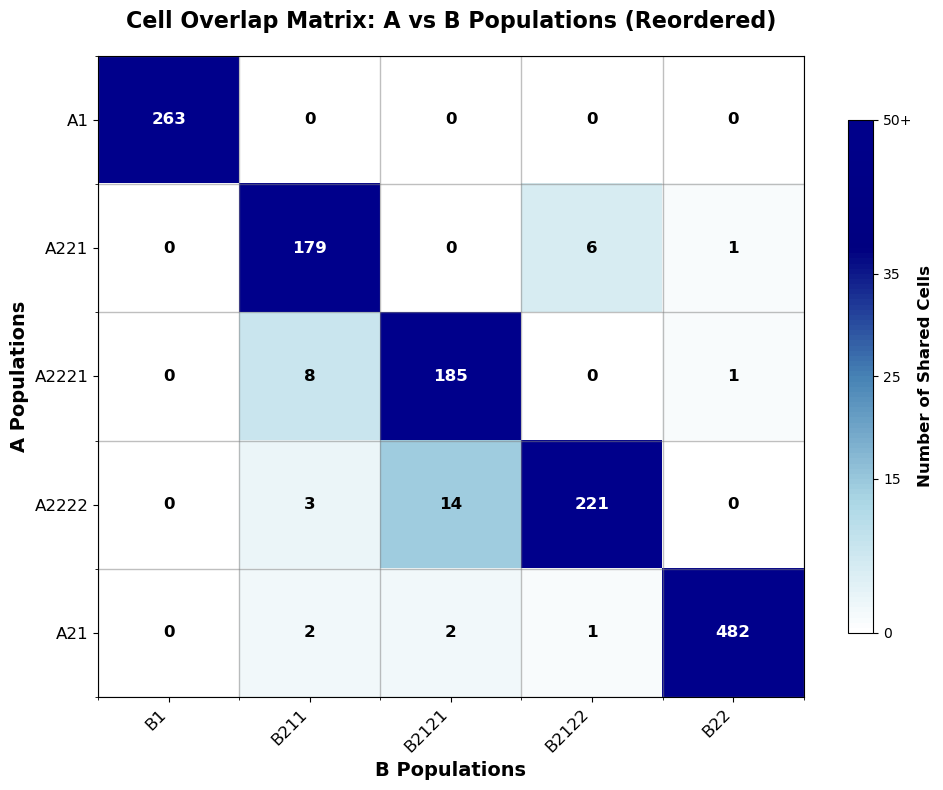

In [17]:
overlap_df = plot_overlap_matrix_figure(A_dict, B_dict, name1="A", name2="B")


Overlap Matrix (A rows vs B cols):
Pop          C11   C1211   C1212    C122      C2
A1             0       0       0       0     263
A21          483       1       2       1       0
A221           1       5       0     180       0
A2221          0       5     182       7       0
A2222          0     225      11       2       0


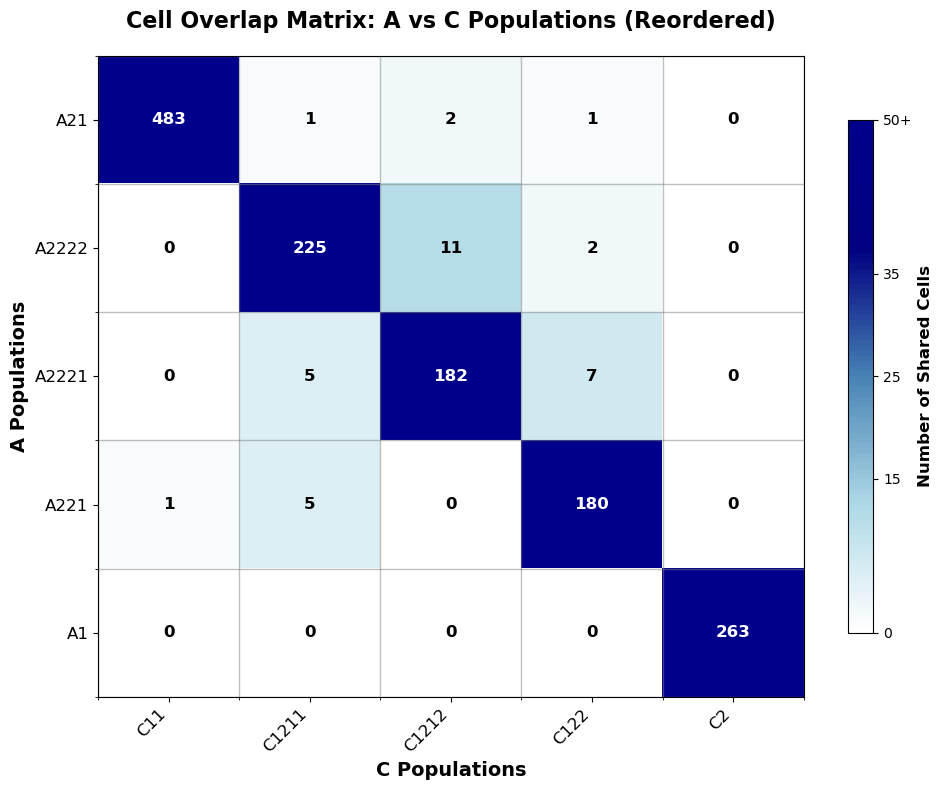

In [18]:
overlap_df = plot_overlap_matrix_figure(A_dict, C_dict, name1="A", name2="C")


Overlap Matrix (A rows vs B cols):
Pop           B1    B211   B2121   B2122     B22
A1           263       0       0       0       0
A21            0       2       2       1     482
A221           0     179       0       6       1
A2221          0       8     185       0       1
A2222          0       3      14     221       0


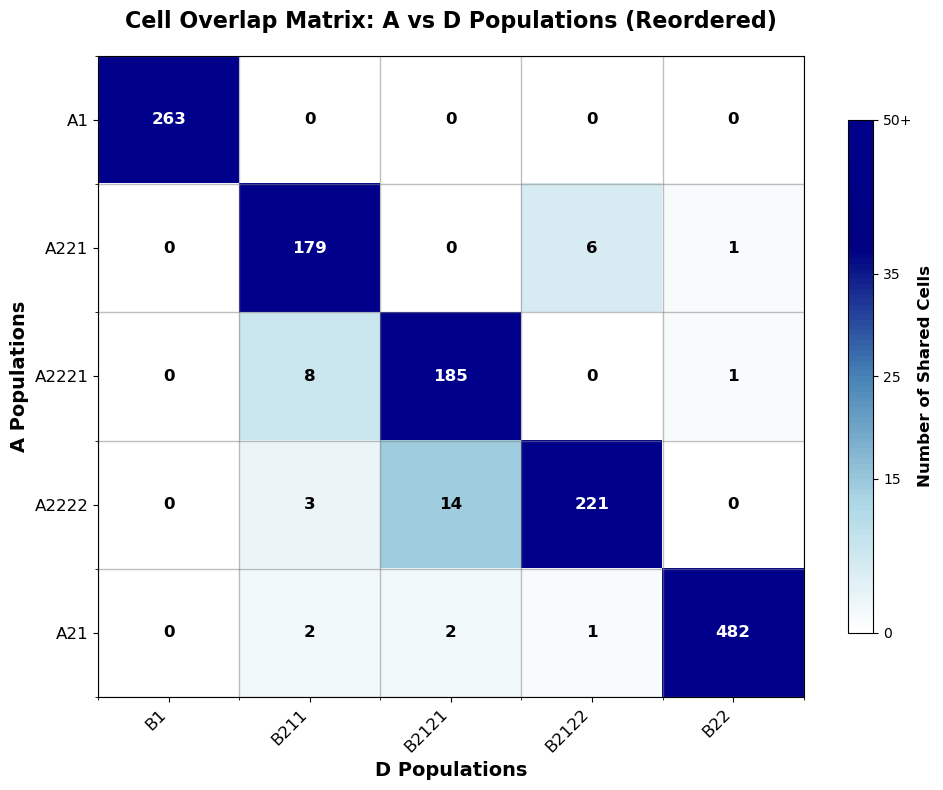

In [19]:
overlap_df = plot_overlap_matrix_figure(A_dict, B_dict, name1="A", name2="D")

In [20]:
# Prepare the data - create the data DataFrame with segment info
data = bincounts[["chrom","abstart", "abend"]].copy()
data_no_WGS = bincounts_no_WGS[["chrom","abstart", "abend"]].copy()
for cell in cells:
    if cell in bincounts.columns:
        data[cell] = bincounts[cell].values
        data_no_WGS[cell] = bincounts_no_WGS[cell].values
data["lengths"] = data["abend"] - data["abstart"]
data_no_WGS["lengths"] = data_no_WGS["abend"] - data_no_WGS["abstart"]

# Get just the cell count data for analysis
all_data = data[cells].copy()
all_data_no_WGS = data_no_WGS[cells].copy()

/var/folders/p3/qk0s0_l96v7679y441dyvbx80000gn/T/ipykernel_29421/166721051.py:6: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  data[cell] = bincounts[cell].values
/var/folders/p3/qk0s0_l96v7679y441dyvbx80000gn/T/ipykernel_29421/166721051.py:7: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  data_no_WGS[cell] = bincounts_no_WGS[cell].values
/var/folders/p3/qk0s0_l96v7679y441dyvbx80000gn/T/ipykernel_29421/166721051.py:6: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many ti

In [21]:
# Identify normal populations and compute ratios for both A and B populations
print("=== Population Set A Analysis ===")
avg_counts_A, ratios_A, normal_A = compute_average_segment_counts(all_data, A_dict, data)
relative_counts_A = compute_read_counts_relative_to_normal(all_data, A_dict, normal_A)
print("=== Population Set B Analysis ===")
avg_counts_B, ratios_B, normal_B = compute_average_segment_counts(all_data, B_dict, data)
relative_counts_B = compute_read_counts_relative_to_normal(all_data, B_dict, normal_B)
print("=== Population Set C Analysis ===")
avg_counts_C, ratios_C, normal_C = compute_average_segment_counts(all_data, C_dict, data)
relative_counts_C = compute_read_counts_relative_to_normal(all_data, C_dict, normal_C)
print("=== Population Set D Analysis ===")
avg_counts_D, ratios_D, normal_D = compute_average_segment_counts(all_data, D_dict, data)
relative_counts_D = compute_read_counts_relative_to_normal(all_data, D_dict, normal_D)



=== Population Set A Analysis ===
Normal population identified as: A1
Mean read count ratio for population A1 relative to normal (A1): 1.00
Mean read count ratio for population A21 relative to normal (A1): 1.04
Mean read count ratio for population A221 relative to normal (A1): 1.27
Mean read count ratio for population A2221 relative to normal (A1): 1.29
Mean read count ratio for population A2222 relative to normal (A1): 1.13
=== Population Set B Analysis ===
Normal population identified as: B1
Mean read count ratio for population B1 relative to normal (B1): 1.00
Mean read count ratio for population B211 relative to normal (B1): 1.30
Mean read count ratio for population B2121 relative to normal (B1): 1.26
Mean read count ratio for population B2122 relative to normal (B1): 1.15
Mean read count ratio for population B22 relative to normal (B1): 1.03
=== Population Set C Analysis ===
Normal population identified as: C2
Mean read count ratio for population C11 relative to normal (C2): 1.03
M

In [22]:
#Add normal to the A_df population assignments
A_df["normal_population"] = (A_df['population'] == normal_A)
B_df["normal_population"] = (B_df['population'] == normal_B)
C_df["normal_population"] = (C_df['population'] == normal_C)
D_df["normal_population"] = (D_df['population'] == normal_D)

In [23]:
A_df.to_csv(f"../data/{tumor}/{tumor}_new_population_assignments_A.txt", sep="\t", index = False)
B_df.to_csv(f"../data/{tumor}/{tumor}_new_population_assignments_B.txt", sep="\t", index = False)
C_df.to_csv(f"../data/{tumor}/{tumor}_new_population_assignments_C.txt", sep="\t", index = False)
D_df.to_csv(f"../data/{tumor}/{tumor}_new_population_assignments_D.txt", sep="\t", index = False)

In [24]:
# A_df = pd.read_csv(f"../data/{tumor}/{tumor}_population_assignments_A_WGS_bins.txt", sep="\t")
# A_dict = {}
# for cluster in A_df['population'].unique():
#     print(cluster)
#     cells_in_cluster = A_df[A_df['population'] == cluster]['cell'].tolist()
#     A_dict[cluster] = {
#         'cells': cells_in_cluster
#     }
# avg_counts_A, ratios_A, normal_A = compute_average_segment_counts(all_data, A_dict, data)
# relative_counts_A = compute_read_counts_relative_to_normal(all_data, A_dict, normal_A)

In [25]:
data_lengths = data["abend"] - data["abstart"]

In [26]:
# plot_uniformity_histograms_nice(
#     all_data, 
#     A_dict, 
#     data_lengths, 
#     uniformity_data=None,  # Optional: will compute if not provided
#     title_prefix="Populations from WGS bins - ", 
#     figsize=(12, 8)
# )

In [27]:
# Display the ratios dataframes
print("Population A ratios:")
print(ratios_A.head())

print("\nPopulation B ratios:")
print(ratios_B.head())

Population A ratios:
  chrom      start        end  segment_id  A1_ratio  A21_ratio  A221_ratio  \
0  chr1          0  112738004           0       1.0   1.090765    1.138116   
1  chr1  113307844  120035598           1       1.0   1.408124    1.576296   
2  chr1  120811216  144545019           2       1.0   1.055048    1.231293   
3  chr1  145591762  198579918           3       1.0   1.154755    1.505483   
4  chr1  199117203  248389233           4       1.0   1.124368    1.464537   

   A2221_ratio  A2222_ratio  
0     1.065714     0.840268  
1     1.479546     1.224765  
2     1.217190     1.064483  
3     1.448318     1.224593  
4     1.409645     1.222582  

Population B ratios:
  chrom      start        end  segment_id  B1_ratio  B211_ratio  B2121_ratio  \
0  chr1          0  112738004           0       1.0    1.160338     1.026280   
1  chr1  113307844  120035598           1       1.0    1.613885     1.422235   
2  chr1  120811216  144545019           2       1.0    1.262544     

In [28]:
relative_counts_A

{'A1': np.float64(1.0),
 'A21': np.float64(1.0358004063627795),
 'A221': np.float64(1.2719253133795578),
 'A2221': np.float64(1.2948690900661435),
 'A2222': np.float64(1.1309495049634581)}

In [29]:
# Get all population ratio columns (excluding normal population) for A
pop_ratio_cols_A = [col for col in ratios_A.columns if col.endswith('_ratio') and col != f"{normal_A}_ratio"]

# Store results
ploidy_results_A = {}
profile_dfs_A = {}

print(f"Normal population: {normal_A}")
print(f"Populations to optimize: {[col.replace('_ratio', '') for col in pop_ratio_cols_A]}")

for pop_col in pop_ratio_cols_A:
    pop_name = pop_col.replace('_ratio', '')
    print(f"\n{'='*50}")
    print(f"Optimizing ploidy for population: {pop_name}")
    
    # Compute optimal ploidy
    optimal_m, min_cost, results_df, cost_results, _ = compute_optimal_ploidy_and_profile(
        ratios_A, 
        relative_counts_A,
        pop_col, 
        m_range=[1.5, 6], 
        step_size=0.1
    )
    
    # Store results
    ploidy_results_A[pop_name] = {
        'optimal_multiplier': optimal_m,
        'min_cost': min_cost,
        'cost_results': cost_results
    }
    profile_dfs_A[pop_name] = results_df
    
    print(f"Optimal multiplier for {pop_name}: {optimal_m:.3f}")

Normal population: A1
Populations to optimize: ['A21', 'A221', 'A2221', 'A2222']

Optimizing ploidy for population: A21

Optimal Results for A21:
Optimal multiplier (m): 2.700
Minimum cost: 6.48e+07
Average copy number: 2.80
Found 4 local minima
Optimal multiplier for A21: 2.700

Optimizing ploidy for population: A221

Optimal Results for A221:
Optimal multiplier (m): 2.800
Minimum cost: 1.77e+08
Average copy number: 3.61
Found 5 local minima
Optimal multiplier for A221: 2.800

Optimizing ploidy for population: A2221

Optimal Results for A2221:
Optimal multiplier (m): 2.200
Minimum cost: 9.82e+07
Average copy number: 2.79
Found 5 local minima
Optimal multiplier for A2221: 2.200

Optimizing ploidy for population: A2222

Optimal Results for A2222:
Optimal multiplier (m): 2.400
Minimum cost: 6.44e+07
Average copy number: 2.72
Found 4 local minima
Optimal multiplier for A2222: 2.400


In [30]:
# In your existing ploidy optimization loop, just modify the function call:
for pop_col in pop_ratio_cols_A:
    pop_name = pop_col.replace('_ratio', '')
    print(f"\n{'='*50}")
    print(f"Optimizing ploidy for population: {pop_name}")
    
    # Get local minima along with the usual results
    optimal_m, min_cost, results_df, cost_results, local_minima = compute_optimal_ploidy_and_profile(
        ratios_A, 
        relative_counts_A,
        pop_col, 
        m_range=[1.5, 6], 
        step_size=0.1, 
        find_local_minima=True,  # Add this parameter
        window_size=2           # Optional: adjust window size
    )
    
    # Store results including local minima
    ploidy_results_A[pop_name] = {
        'optimal_multiplier': optimal_m,
        'min_cost': min_cost,
        'cost_results': cost_results,
        'local_minima': local_minima  # Add this
    }
    profile_dfs_A[pop_name] = results_df
    
    print(f"Optimal multiplier for {pop_name}: {optimal_m:.3f}")
    print(f"Found {len(local_minima)} local minima: {[f'{m:.2f}' for m, _ in local_minima[:5]]}")


Optimizing ploidy for population: A21

Optimal Results for A21:
Optimal multiplier (m): 2.700
Minimum cost: 6.48e+07
Average copy number: 2.80
Found 4 local minima
Optimal multiplier for A21: 2.700
Found 4 local minima: ['2.70', '5.50', '3.70', '4.40']

Optimizing ploidy for population: A221

Optimal Results for A221:
Optimal multiplier (m): 2.800
Minimum cost: 1.77e+08
Average copy number: 3.61
Found 5 local minima
Optimal multiplier for A221: 2.800
Found 5 local minima: ['2.10', '2.80', '4.10', '4.90', '3.20']

Optimizing ploidy for population: A2221

Optimal Results for A2221:
Optimal multiplier (m): 2.200
Minimum cost: 9.82e+07
Average copy number: 2.79
Found 5 local minima
Optimal multiplier for A2221: 2.200
Found 5 local minima: ['2.20', '4.40', '5.40', '3.10', '3.90']

Optimizing ploidy for population: A2222

Optimal Results for A2222:
Optimal multiplier (m): 2.400
Minimum cost: 6.44e+07
Average copy number: 2.72
Found 4 local minima
Optimal multiplier for A2222: 2.400
Found 4 


Plotting results for population: A21


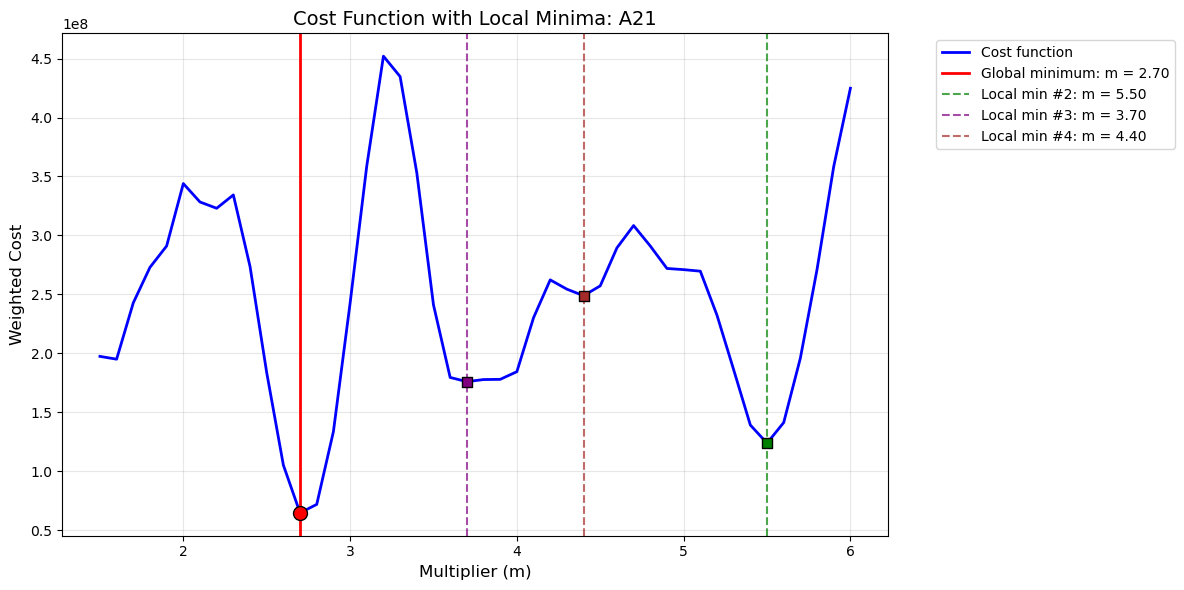


Local Minima Summary for A21:
--------------------------------------------------
#1: m = 2.70, cost = 6.48e+07 (GLOBAL)
#2: m = 5.50, cost = 1.24e+08
#3: m = 3.70, cost = 1.76e+08
#4: m = 4.40, cost = 2.49e+08


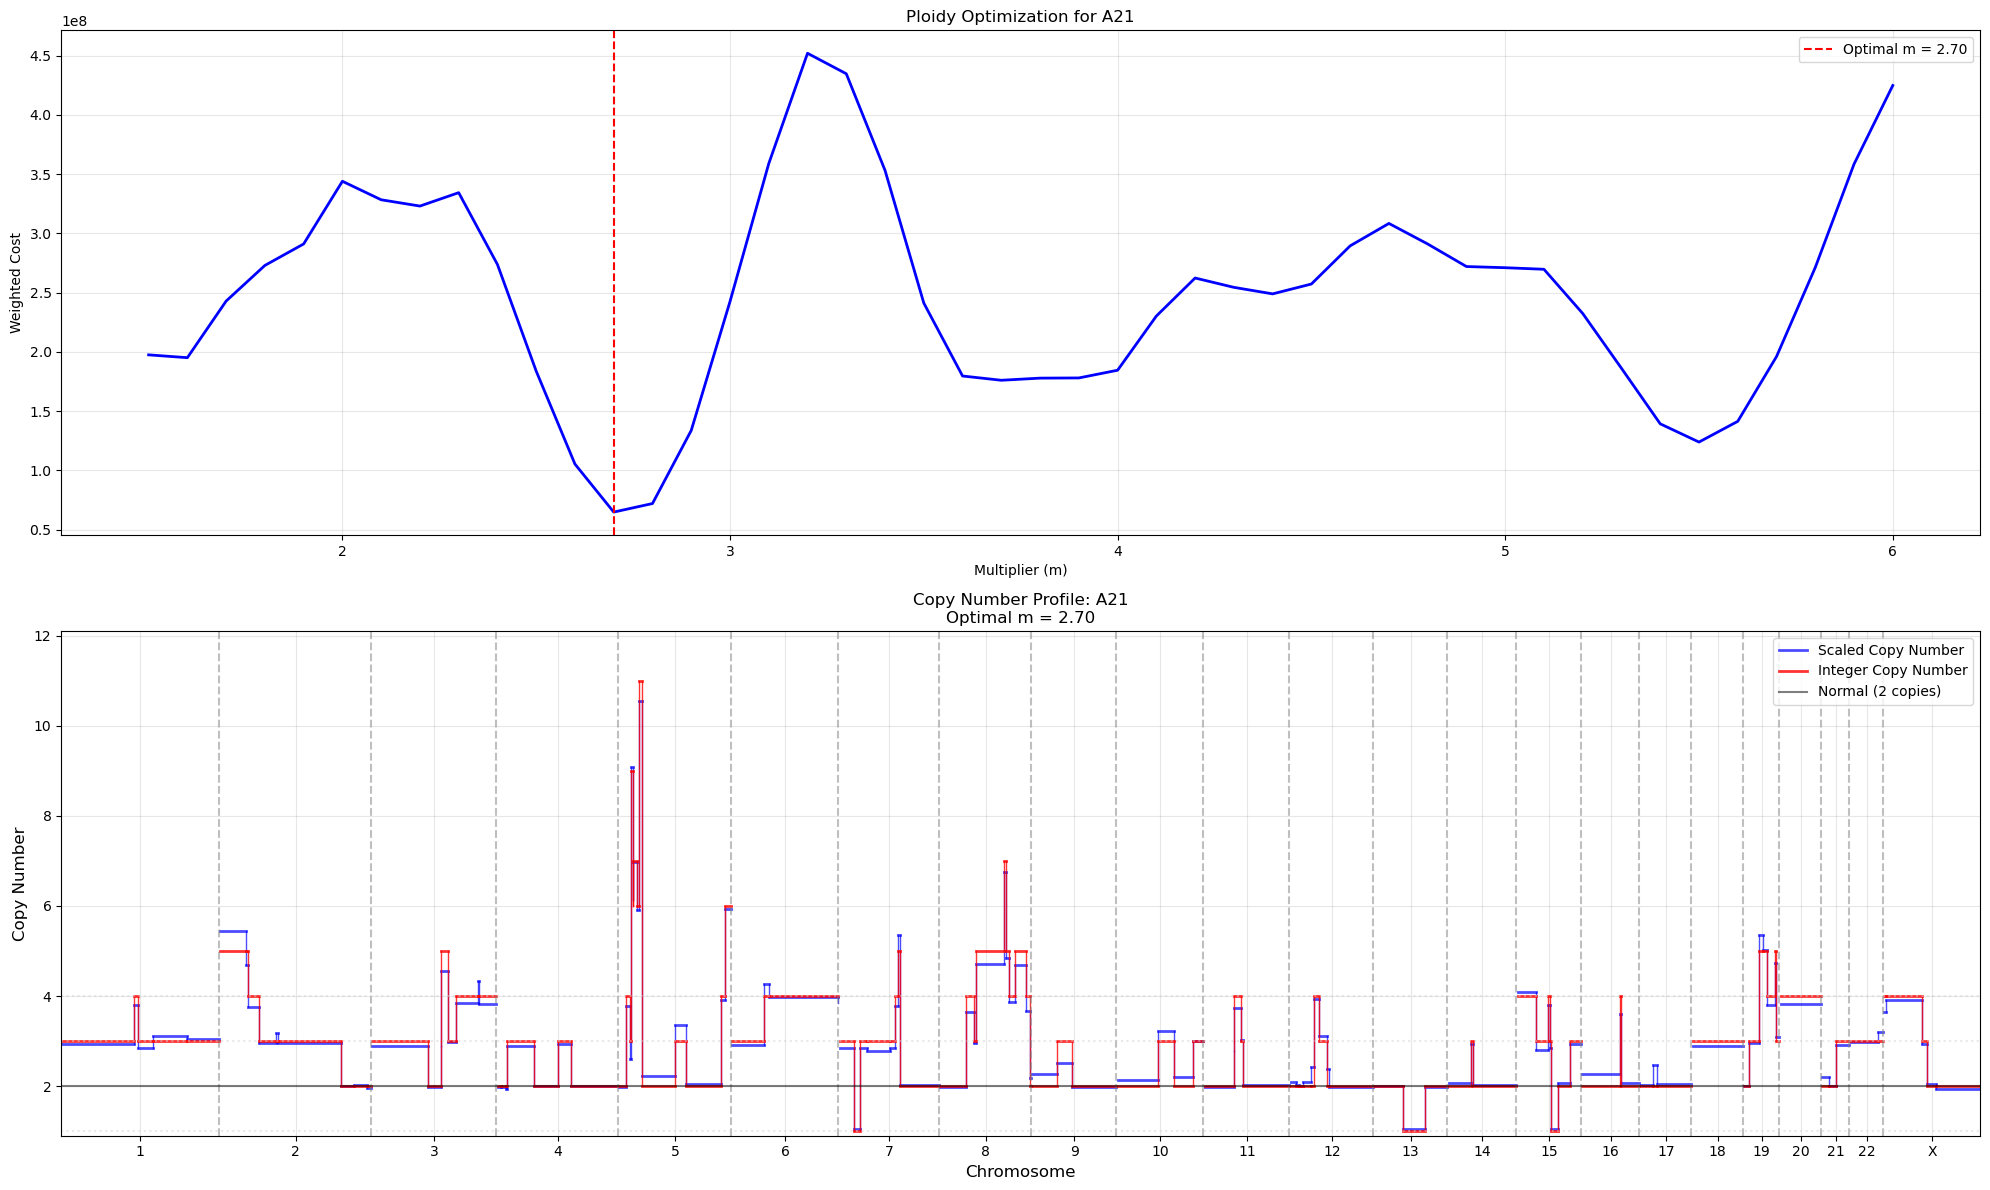

Completed plots for A21

Plotting results for population: A221


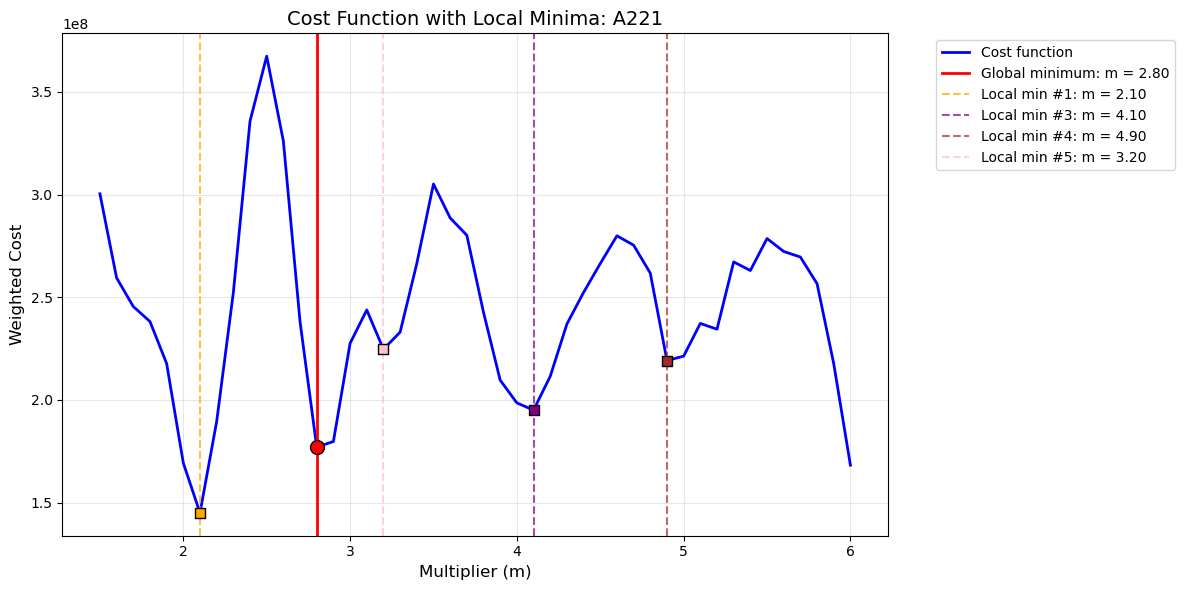


Local Minima Summary for A221:
--------------------------------------------------
#1: m = 2.10, cost = 1.45e+08
#2: m = 2.80, cost = 1.77e+08 (GLOBAL)
#3: m = 4.10, cost = 1.95e+08
#4: m = 4.90, cost = 2.19e+08
#5: m = 3.20, cost = 2.25e+08


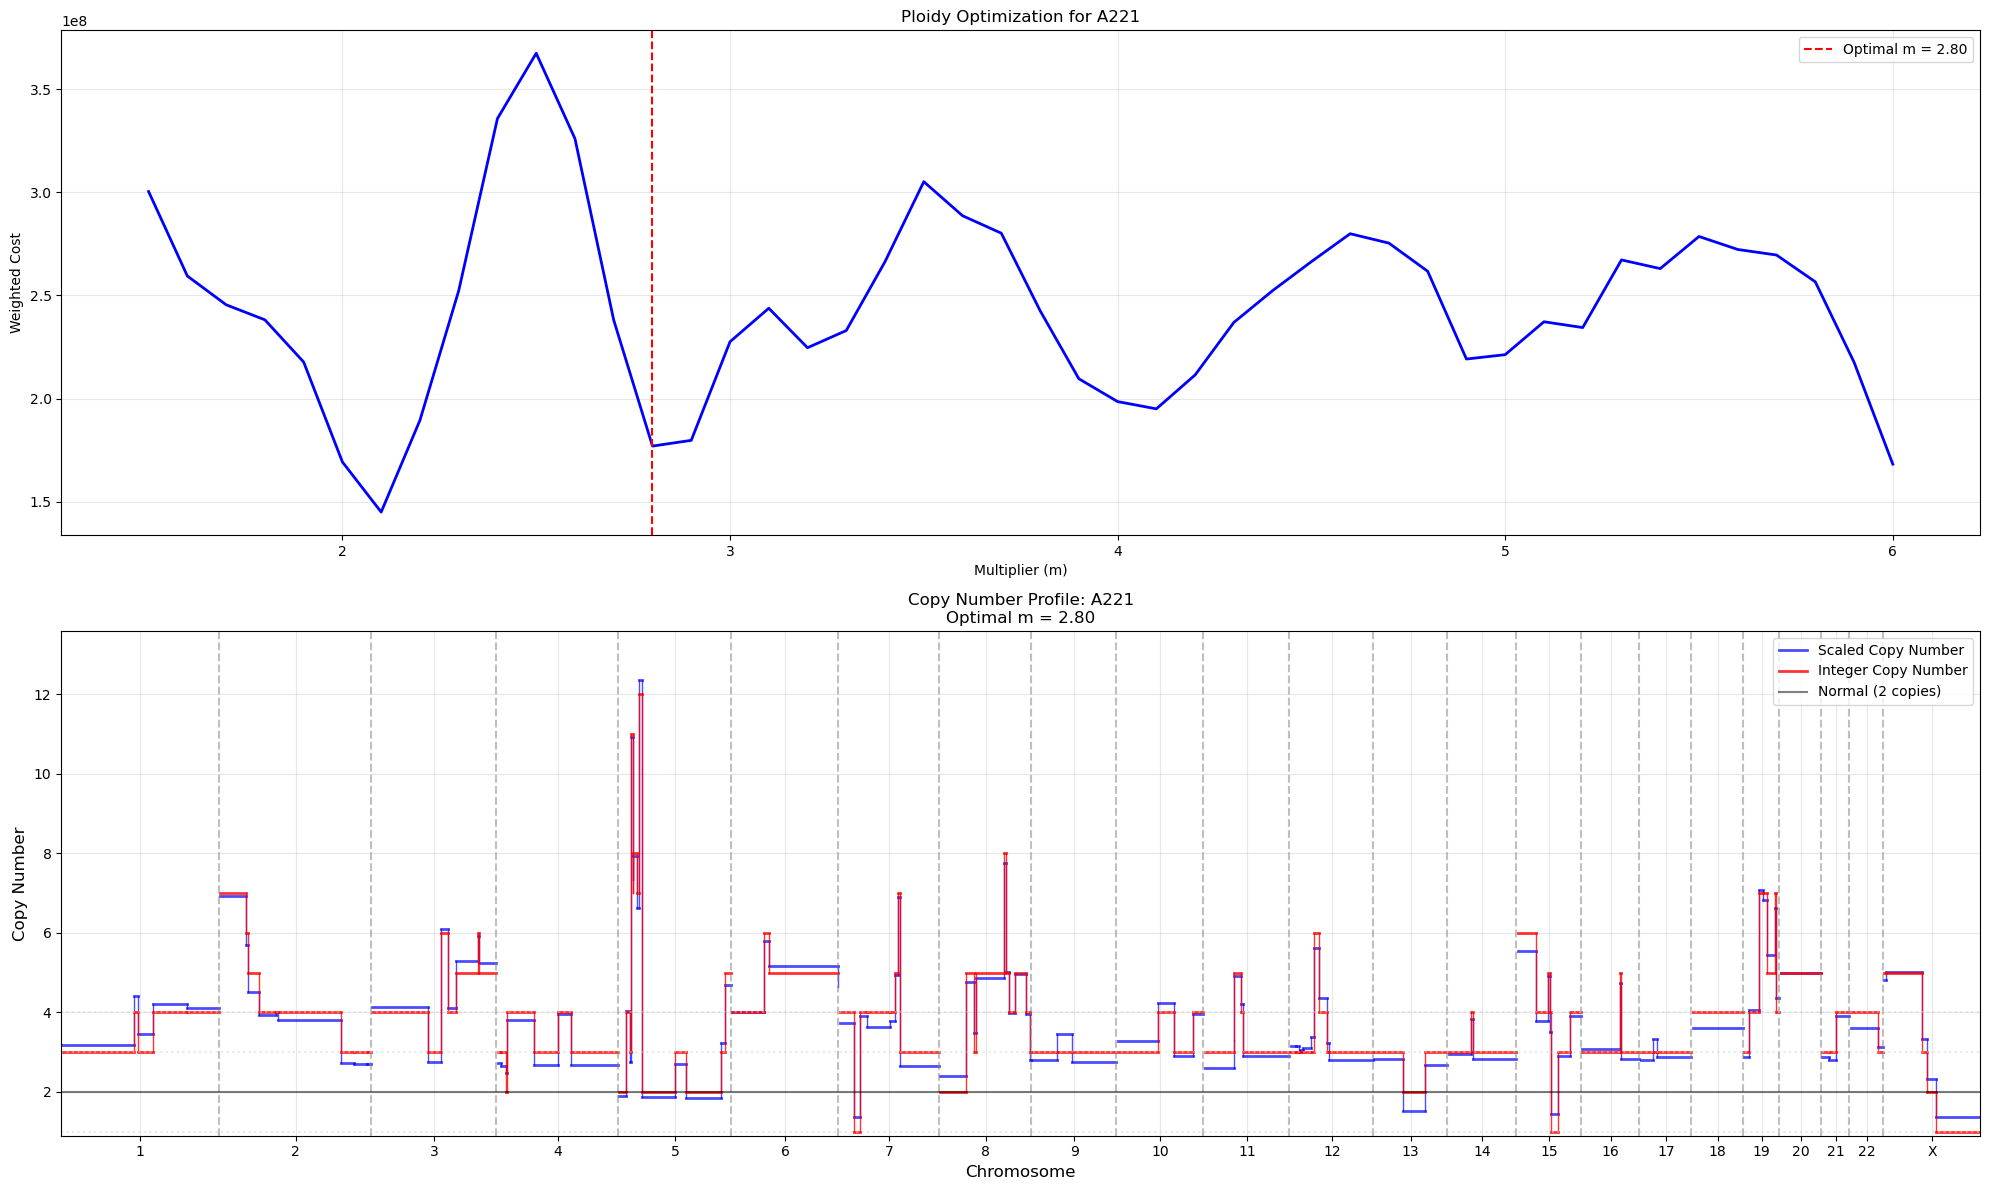

Completed plots for A221

Plotting results for population: A2221


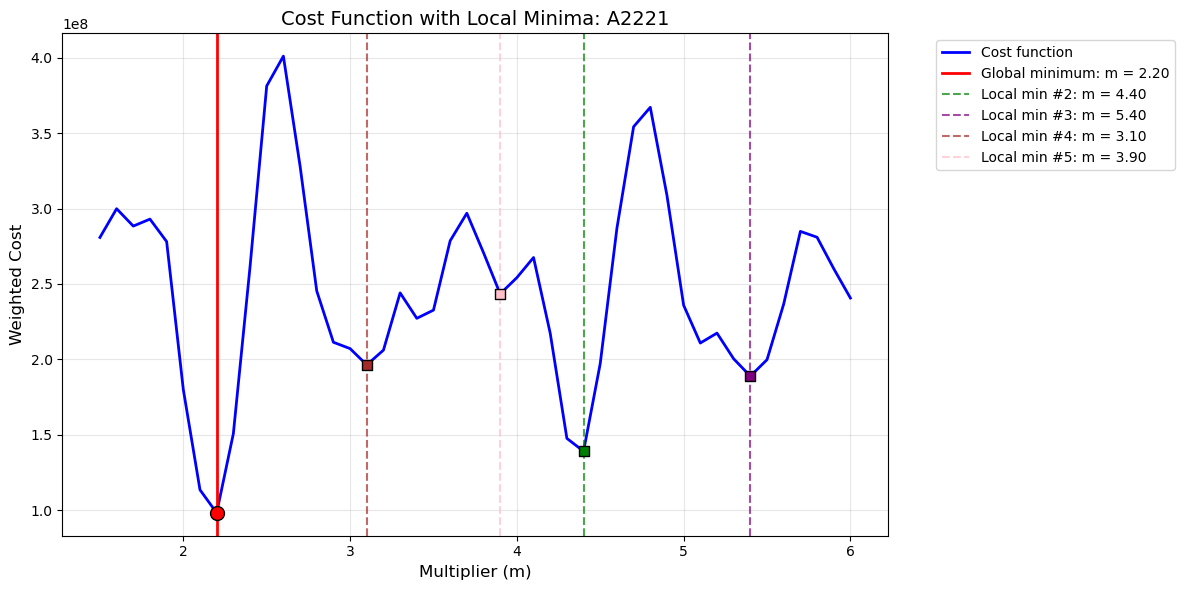


Local Minima Summary for A2221:
--------------------------------------------------
#1: m = 2.20, cost = 9.82e+07 (GLOBAL)
#2: m = 4.40, cost = 1.39e+08
#3: m = 5.40, cost = 1.89e+08
#4: m = 3.10, cost = 1.96e+08
#5: m = 3.90, cost = 2.43e+08


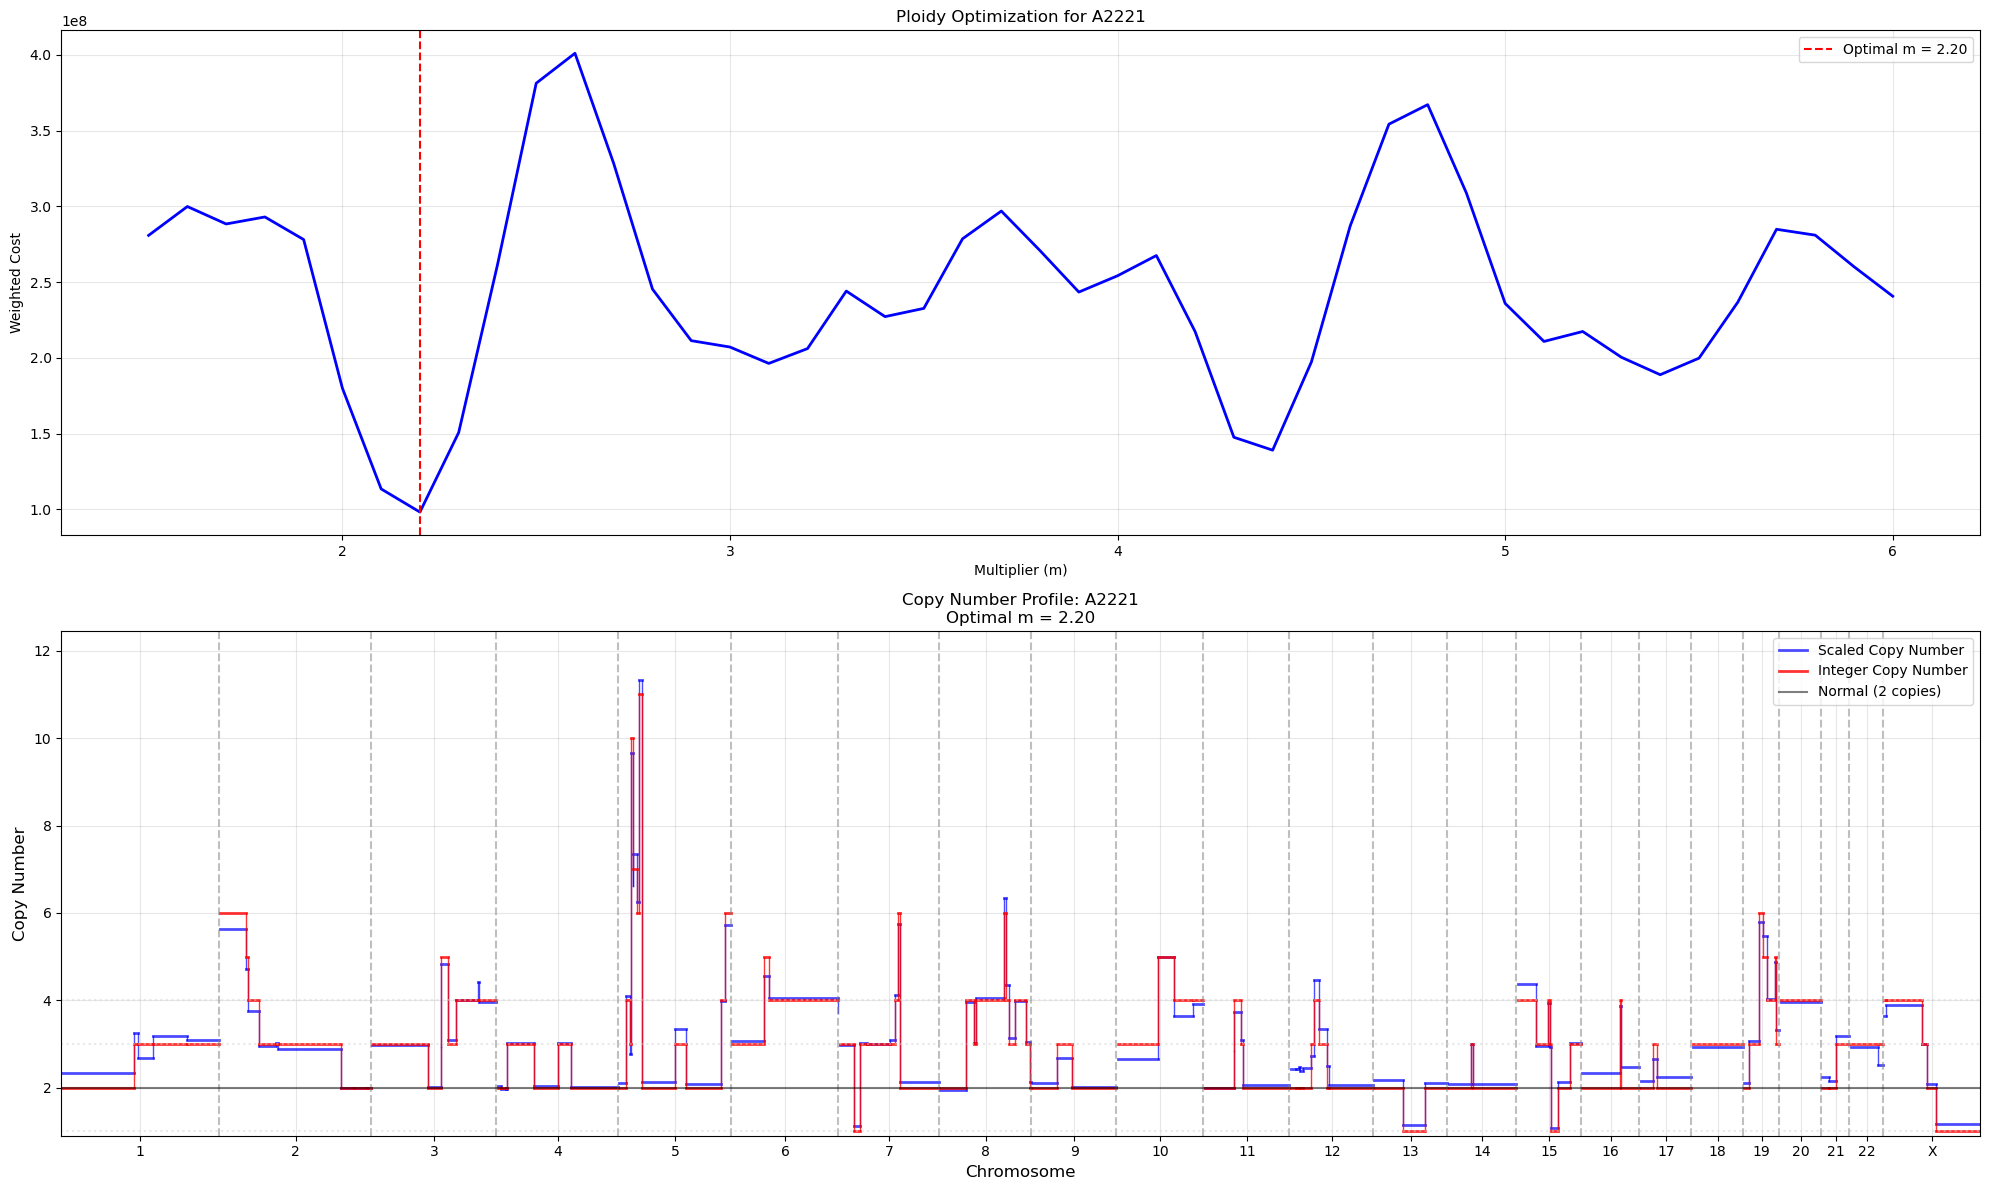

Completed plots for A2221

Plotting results for population: A2222


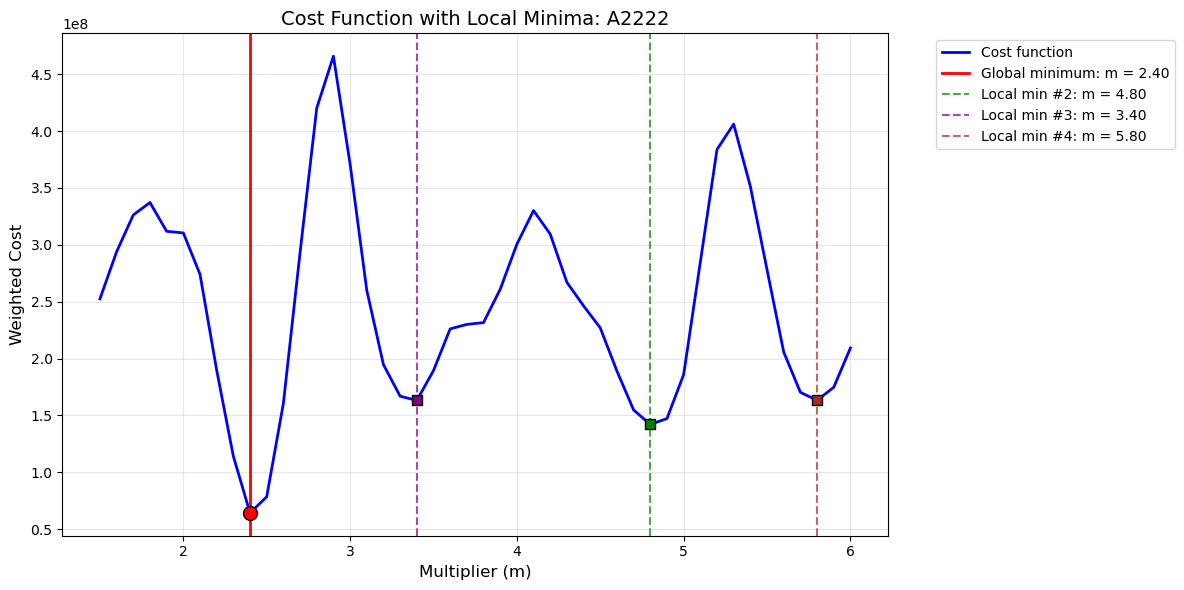


Local Minima Summary for A2222:
--------------------------------------------------
#1: m = 2.40, cost = 6.44e+07 (GLOBAL)
#2: m = 4.80, cost = 1.42e+08
#3: m = 3.40, cost = 1.63e+08
#4: m = 5.80, cost = 1.63e+08


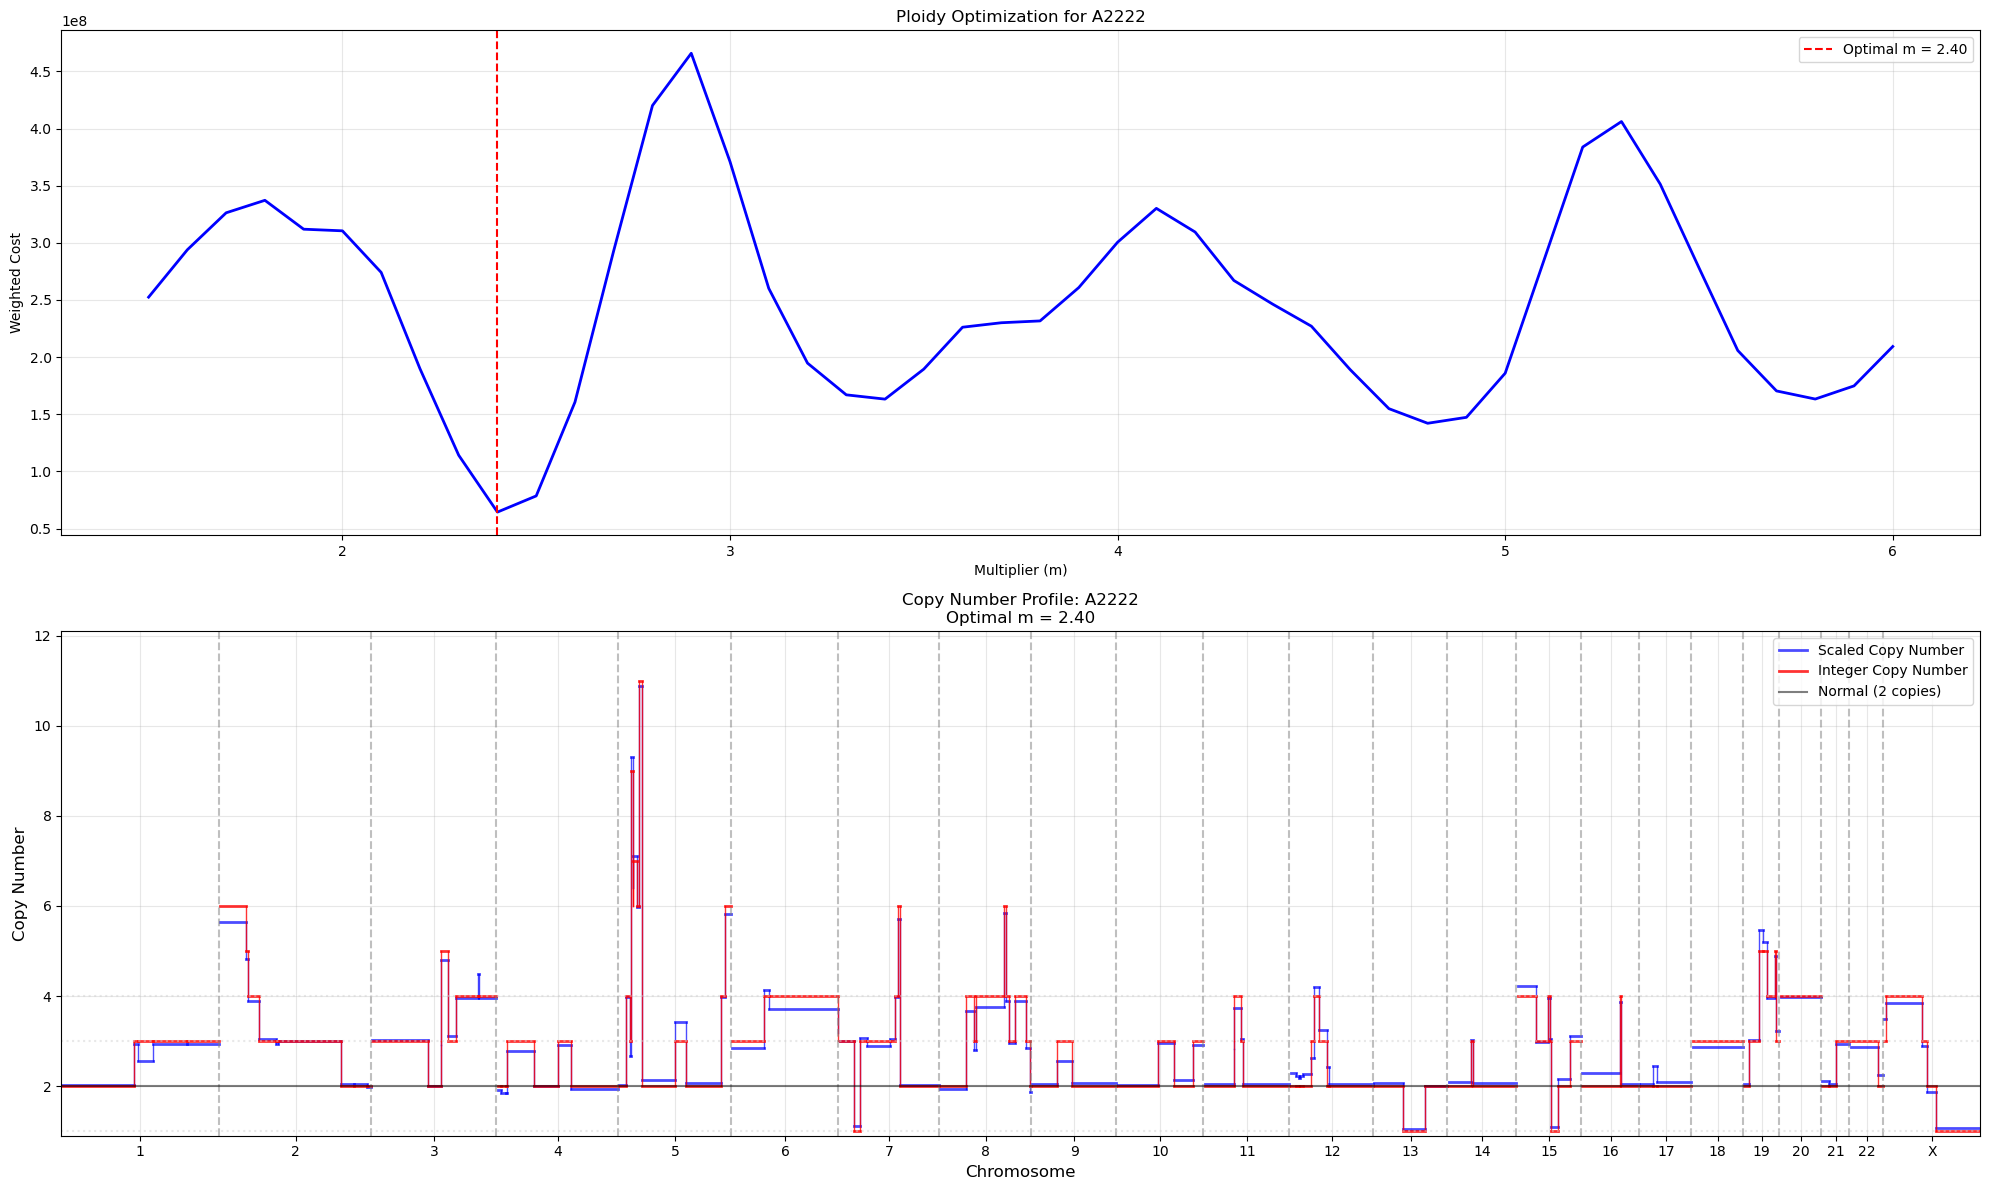

Completed plots for A2222


In [31]:
# Test the plotting functions on your ploidy results
for pop_name in ploidy_results_A.keys():
    print(f"\n{'='*60}")
    print(f"Plotting results for population: {pop_name}")
    
    # Get the results for this population
    results = ploidy_results_A[pop_name]
    profile_df = profile_dfs_A[pop_name]
    
    # 1. Plot cost function with local minima
    plot_cost_function_with_minima(
        cost_results=results['cost_results'],
        local_minima=results['local_minima'],
        pop_name=pop_name,
        optimal_m=results['optimal_multiplier']
    )
    
    # 2. Plot the full ploidy optimization (cost function + copy number profile)
    pop_col = f"{pop_name}_ratio"  # Reconstruct the column name
    plot_ploidy_optimization(
        results_df=profile_df,
        cost_results=results['cost_results'],
        optimal_m=results['optimal_multiplier'],
        pop_col=pop_col
    )
    
    print(f"Completed plots for {pop_name}")

In [32]:
import os
import pandas as pd

# Define the parquet file path
parquet_file = f"../data/{tumor}/hap_count_df.parquet"

# Check if parquet file exists, if so load it, otherwise create and save it
if os.path.exists(parquet_file):
    print("Loading hap_count_df from parquet file...")
    hap_count_df = pd.read_parquet(parquet_file)
    print(f"Loaded hap_count_df with shape: {hap_count_df.shape}")
else:
    print("Parquet file not found. Creating hap_count_df from source data...")
    
    hap_count_df = pd.read_csv(f"/mnt/wigstore6/user/ranade/binless_clustering/DNA_alone/{tumor}/per_cell_hap_count.txt", sep = "\t")
    binning = pd.read_csv("/mnt/wigstore3/user/kendall/hg19.50mer/hg19.varbin.gc.content.2.5k.bowtie.k50.txt", sep='\t')
    bin_loc_dict = dict(zip(binning.index, binning["bin.start.abspos"]))
    chrom_dict = dict(zip(binning.index, binning["bin.chrom"]))

    hap_count_df["abspos"] = hap_count_df["bin"].apply(lambda x : bin_loc_dict[x])
    hap_count_df["chrom"] = hap_count_df["bin"].apply(lambda x : chrom_dict[x])
    hap_count_df= hap_count_df[["chrom", "abspos","bin", "cell", "hap_count","Total"]]

    print(f"Created hap_count_df with shape: {hap_count_df.shape}")
    
    # Save as parquet for future use
    print("Saving hap_count_df as parquet file...")
    hap_count_df.to_parquet(parquet_file, index=False)
    
    # Check file size
    file_size = os.path.getsize(parquet_file)
    print(f"Saved parquet file: {file_size:,} bytes ({file_size/1024**2:.2f} MB)")

print("hap_count_df ready for analysis!")

Loading hap_count_df from parquet file...
Loaded hap_count_df with shape: (6055792, 6)
hap_count_df ready for analysis!


In [33]:
hap_count_df.head()

,chrom,abspos,bin,cell,hap_count,Total
0,chr1,0,0,TAGTCAGCCTCTGTAAT,13,16
1,chr1,1925685,1,TAGTCAGCCTCTGTAAT,0,0
2,chr1,3106884,2,TAGTCAGCCTCTGTAAT,3,5
3,chr1,4351684,3,TAGTCAGCCTCTGTAAT,0,0
4,chr1,5438445,4,TAGTCAGCCTCTGTAAT,0,0


In [34]:
bin_to_chrom_dict = dict(zip(hap_count_df[["chrom", "bin"]].drop_duplicates()["bin"].values, hap_count_df[["chrom", "bin"]].drop_duplicates()["chrom"].values))

In [35]:
example = list(A_dict.keys())[1]

In [36]:
# # Example usage for A211 with global min 2.4 and local min 3.1
# plot_ploidy_comparison(
#     results_df=profile_dfs_A[example],
#     cost_results=ploidy_results_A[example]['cost_results'],
#     optimal_m=2.4,  # or use ploidy_results_A[example]['optimal_multiplier']
#     local_m=3.1,   # pick from ploidy_results_A[example]['local_minima']
#     pop_col=f'{example}_ratio'
# )

In [37]:
#Get all cells in example
example_cells = A_dict[example]['cells']
#Filter hap_count_df for these cells
example_hap_df = hap_count_df[hap_count_df['cell'].isin(example_cells)].copy()
# compute haplotype ratio for each bin and abspos (sum of hap_count over all cells/ sum of Total over all cells)
example_hap_ratio = example_hap_df.groupby(['bin', 'abspos']).agg({'hap_count':'sum', 'Total':'sum'}).reset_index()
example_hap_ratio['hap_ratio'] = example_hap_ratio['hap_count'] / example_hap_ratio['Total']
example_hap_ratio['folded'] = example_hap_ratio['hap_ratio'].apply(lambda x: min(x, 1-x))
# Add chromosome information    
example_hap_ratio["chrom"] = example_hap_ratio["bin"].apply(lambda x : bin_to_chrom_dict[x])

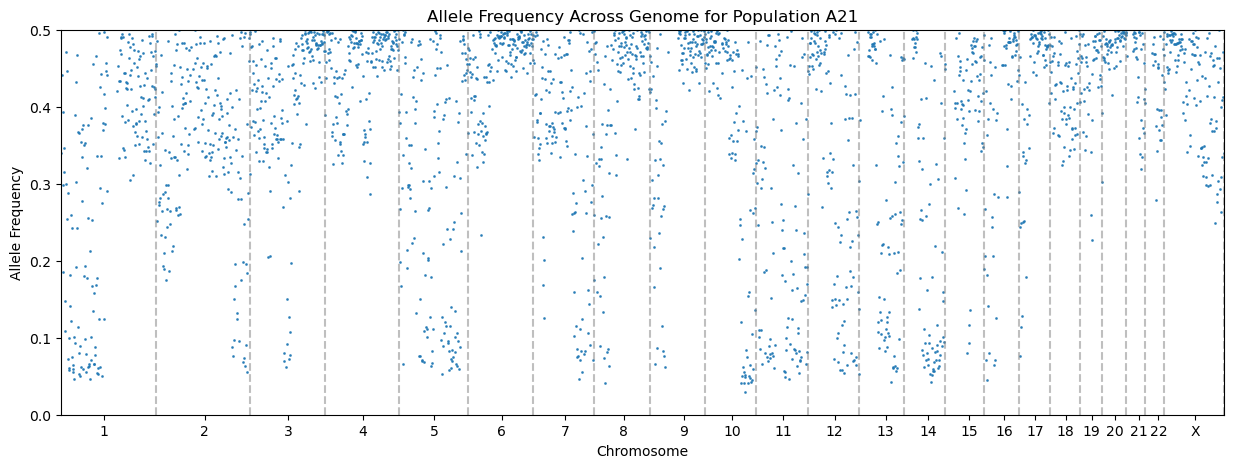

In [38]:
# plot the folded allele frequency along the genome
example_hap_ratio_sorted = example_hap_ratio.sort_values(by=['chrom', 'abspos'])
plt.figure(figsize=(15,5))
plt.scatter(example_hap_ratio_sorted['abspos'], example_hap_ratio_sorted['folded'], s=1, alpha=0.8)
plt.xlabel('Chromosome')
plt.ylabel('Allele Frequency')
plt.title('Allele Frequency Across Genome for Population ' + example)
# Add vertical lines for chromosome boundaries
chrom_boundaries = example_hap_ratio_sorted.groupby('chrom')['abspos'].max()
for boundary in chrom_boundaries:
    plt.axvline(x=boundary, color='grey', linestyle='--', alpha=0.5)
# Add chromosome labels at midpoints
chrom_midpoints = example_hap_ratio_sorted.groupby('chrom')['abspos'].median()
# add chromosome labels along x ticks at midpoints and label them by chromosome number
plt.xticks(chrom_midpoints, [c[3:] for c in chrom_midpoints.index], rotation=0)
# Set y-axis limits to focus on 0 to 0.5

plt.ylim(0, 0.5)
plt.xlim(example_hap_ratio_sorted['abspos'].min(), example_hap_ratio_sorted['abspos'].max())
plt.show()

In [39]:
hap_df_dict = {}
hap_summary_df = pd.DataFrame()
for pop_name in A_dict.keys():
    #Get all cells in example
    example_cells = A_dict[pop_name]['cells']
    #Filter hap_count_df for these cells
    example_hap_df = hap_count_df[hap_count_df['cell'].isin(example_cells)].copy()
    # compute haplotype ratio for each bin and abspos (sum of hap_count over all cells/ sum of Total over all cells)
    example_hap_ratio = example_hap_df.groupby(['bin', 'abspos']).agg({'hap_count':'sum', 'Total':'sum'}).reset_index()
    example_hap_ratio['hap_ratio_'+pop_name] = example_hap_ratio['hap_count'] / example_hap_ratio['Total']
    example_hap_ratio.rename(columns={'hap_count': 'hap_count_'+pop_name, 'Total': 'Total_'+pop_name}, inplace=True)
    example_hap_ratio['folded_'+pop_name] = example_hap_ratio['hap_ratio_'+pop_name].apply(lambda x: min(x, 1-x))
    # Add chromosome information    
    example_hap_ratio["chrom"] = example_hap_ratio["bin"].apply(lambda x : bin_to_chrom_dict[x])
    example_hap_ratio = example_hap_ratio[["bin", "abspos", "chrom", 'hap_ratio_'+pop_name, 'folded_'+pop_name, 'hap_count_'+pop_name, 'Total_'+pop_name]]
    hap_df_dict[pop_name] = example_hap_ratio.sort_values(by=['chrom', 'abspos'])
    if hap_summary_df.empty:
        hap_summary_df = example_hap_ratio.sort_values(by=['chrom', 'abspos']).copy()
    else:
        hap_summary_df = hap_summary_df.merge(
            example_hap_ratio,
            on=['bin', 'abspos', 'chrom'],
            suffixes=('', f'_{pop_name}')
        )


In [40]:
hap_summary_df

,bin,abspos,chrom,hap_ratio_A1,folded_A1,hap_count_A1,Total_A1,hap_ratio_A21,folded_A21,hap_count_A21,...,hap_count_A221,Total_A221,hap_ratio_A2221,folded_A2221,hap_count_A2221,Total_A2221,hap_ratio_A2222,folded_A2222,hap_count_A2222,Total_A2222
0,0,0,chr1,0.239883,0.239883,409,1705,0.339585,0.339585,1032,...,550,1322,0.585522,0.414478,1650,2818,0.265051,0.265051,339,1279
1,1,1925685,chr1,0.609813,0.390187,1044,1712,0.441434,0.441434,1059,...,307,916,0.482417,0.482417,535,1109,0.432886,0.432886,258,596
2,2,3106884,chr1,0.274621,0.274621,435,1584,0.298512,0.298512,1003,...,433,1376,0.328346,0.328346,417,1270,0.234525,0.234525,269,1147
3,3,4351684,chr1,0.209135,0.209135,435,2080,0.185953,0.185953,691,...,433,1668,0.286214,0.286214,409,1429,0.158306,0.158306,243,1535
4,4,5438445,chr1,0.666181,0.333819,914,1372,0.607129,0.392871,1601,...,476,895,0.618203,0.381797,523,846,0.665924,0.334076,598,898
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2483,2483,3029874983,chrX,0.367347,0.367347,288,784,0.334204,0.334204,384,...,96,420,0.293948,0.293948,102,347,0.173913,0.173913,76,437
2484,2484,3031129344,chrX,0.499055,0.499055,528,1058,0.408271,0.408271,543,...,135,322,0.351020,0.351020,172,490,0.477011,0.477011,166,348
2485,2485,3032248949,chrX,0.528285,0.471715,579,1096,0.587126,0.412874,903,...,202,335,0.718978,0.281022,197,274,0.692650,0.307350,311,449
2486,2486,3033693492,chrX,0.561576,0.438424,456,812,0.529221,0.470779,489,...,121,222,0.565749,0.434251,185,327,0.554487,0.445513,173,312


In [41]:
hap_summary_df.to_csv(f"../data/{tumor}/{tumor}_haplotype_summary_by_population_A.txt", sep="\t", index=False)

In [42]:
normal_A

'A1'

In [43]:
#Get all cells in A1
normal_cells = A_dict[normal_A]['cells']
#Filter hap_count_df for these cells
normal_hap_df = hap_count_df[hap_count_df['cell'].isin(normal_cells)].copy()
# compute haplotype ratio for each bin and abspos (sum of hap_count over all cells/ sum of Total over all cells)
normal_hap_ratio = normal_hap_df.groupby(['bin', 'abspos']).agg({'hap_count':'sum', 'Total':'sum'}).reset_index()
normal_hap_ratio['hap_ratio'] = normal_hap_ratio['hap_count'] / normal_hap_ratio['Total']
normal_hap_ratio['folded'] = normal_hap_ratio['hap_ratio'].apply(lambda x: min(x, 1-x))
# Add chromosome information
normal_hap_ratio["chrom"] = normal_hap_ratio["bin"].apply(lambda x: bin_to_chrom_dict[x])

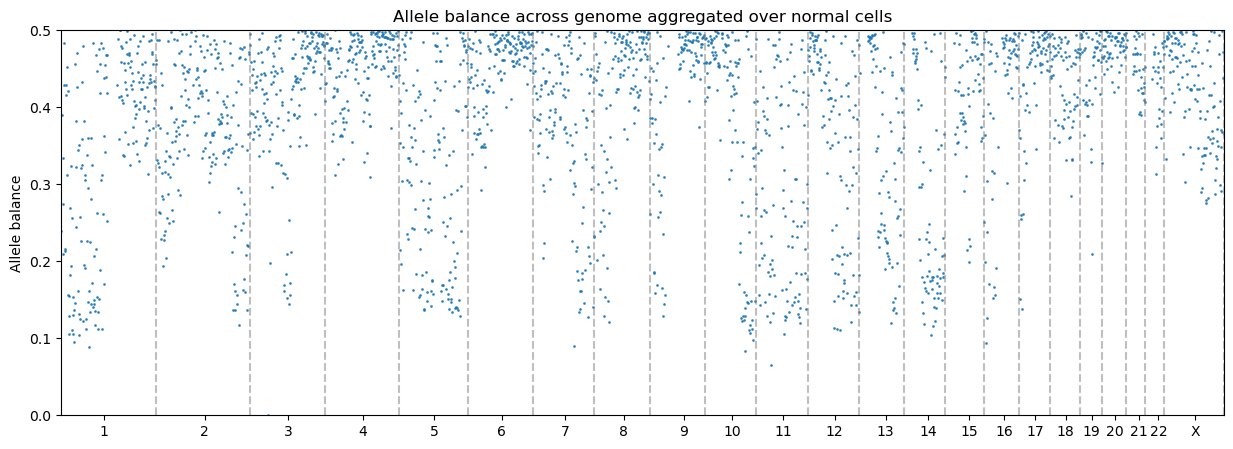

In [44]:
# plot the folded allele frequency along the genome
normal_hap_ratio_sorted = normal_hap_ratio.sort_values(by=['chrom', 'abspos'])
plt.figure(figsize=(15,5))
plt.scatter(normal_hap_ratio_sorted['abspos'], normal_hap_ratio_sorted['folded'], s=1, alpha=0.8)
#plt.xlabel('Chromosome')
plt.ylabel('Allele balance')
plt.title('Allele balance across genome aggregated over normal cells')
# Add vertical lines for chromosome boundaries
chrom_boundaries = normal_hap_ratio_sorted.groupby('chrom')['abspos'].max()
for boundary in chrom_boundaries:
    plt.axvline(x=boundary, color='grey', linestyle='--', alpha=0.5)
# Add chromosome labels at midpoints
chrom_midpoints = normal_hap_ratio_sorted.groupby('chrom')['abspos'].median()
# add chromosome labels along x ticks at midpoints and label them by chromosome number
plt.xticks(chrom_midpoints, [c[3:] for c in chrom_midpoints.index], rotation=0)
# Set y-axis limits to focus on 0 to 0.5

plt.ylim(0, 0.5)
plt.xlim(normal_hap_ratio_sorted['abspos'].min(), normal_hap_ratio_sorted['abspos'].max())
plt.show()

In [45]:
A_df.head()

,cell,population,normal_population
0,AAAACCAAAGTAGTTCT,A1,True
1,AAAACCAACAAGACAAT,A1,True
2,AAAATGGACCATGCACG,A1,True
3,AAAATGTGTTAAGATTA,A1,True
4,AAAGCAGACCATAATGC,A1,True


In [46]:
#Get all tumor cells in (not A1)
tumor_cells = A_df[A_df['population'] != normal_A]['cell'].tolist()
#Filter hap_count_df for these cells
tumor_hap_df = hap_count_df[hap_count_df['cell'].isin(tumor_cells)].copy()
# compute haplotype ratio for each bin and abspos (sum of hap_count over all cells/ sum of Total over all cells)
tumor_hap_ratio = tumor_hap_df.groupby(['bin', 'abspos']).agg({'hap_count':'sum', 'Total':'sum'}).reset_index()
tumor_hap_ratio['hap_ratio'] = tumor_hap_ratio['hap_count'] / tumor_hap_ratio['Total']
tumor_hap_ratio['folded'] = tumor_hap_ratio['hap_ratio'].apply(lambda x: min(x, 1-x))
# Add chromosome information
tumor_hap_ratio["chrom"] = tumor_hap_ratio["bin"].apply(lambda x: bin_to_chrom_dict[x])


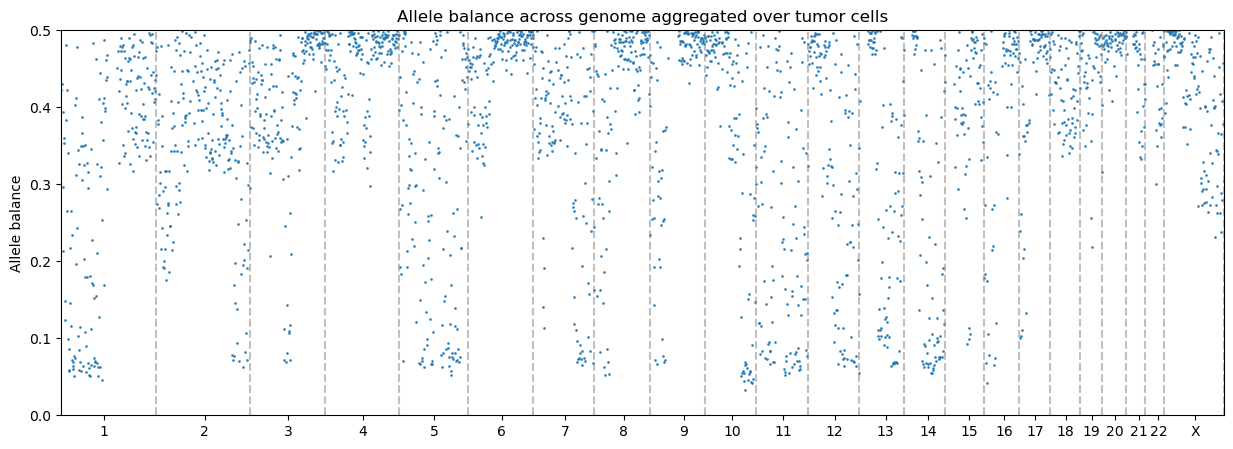

In [47]:
# plot the folded allele frequency along the genome
tumor_hap_ratio_sorted = tumor_hap_ratio.sort_values(by=['chrom', 'abspos'])
plt.figure(figsize=(15,5))
plt.scatter(tumor_hap_ratio_sorted['abspos'], tumor_hap_ratio_sorted['folded'], s=1, alpha=0.8)
#plt.xlabel('Chromosome')
plt.ylabel('Allele balance')
plt.title('Allele balance across genome aggregated over tumor cells')
# Add vertical lines for chromosome boundaries
chrom_boundaries = tumor_hap_ratio_sorted.groupby('chrom')['abspos'].max()
for boundary in chrom_boundaries:
    plt.axvline(x=boundary, color='grey', linestyle='--', alpha=0.5)
# Add chromosome labels at midpoints
chrom_midpoints = tumor_hap_ratio_sorted.groupby('chrom')['abspos'].median()
# add chromosome labels along x ticks at midpoints and label them by chromosome number
plt.xticks(chrom_midpoints, [c[3:] for c in chrom_midpoints.index], rotation=0)
# Set y-axis limits to focus on 0 to 0.5

plt.ylim(0, 0.5)
plt.xlim(tumor_hap_ratio_sorted['abspos'].min(), tumor_hap_ratio_sorted['abspos'].max())
plt.show()

In [48]:
# # Example usage for example with global min 2.4 and local min 3.1
# plot_ploidy_comparison(
#     results_df=profile_dfs_A[example],
#     cost_results=ploidy_results_A[example]['cost_results'],
#     optimal_m=2.4,
#     local_m=3.1,
#     pop_col=example + '_ratio',
#     hap_count_df=hap_count_df,
#     cells=A_dict[example]['cells']
# )


Creating ploidy comparison for population: A21


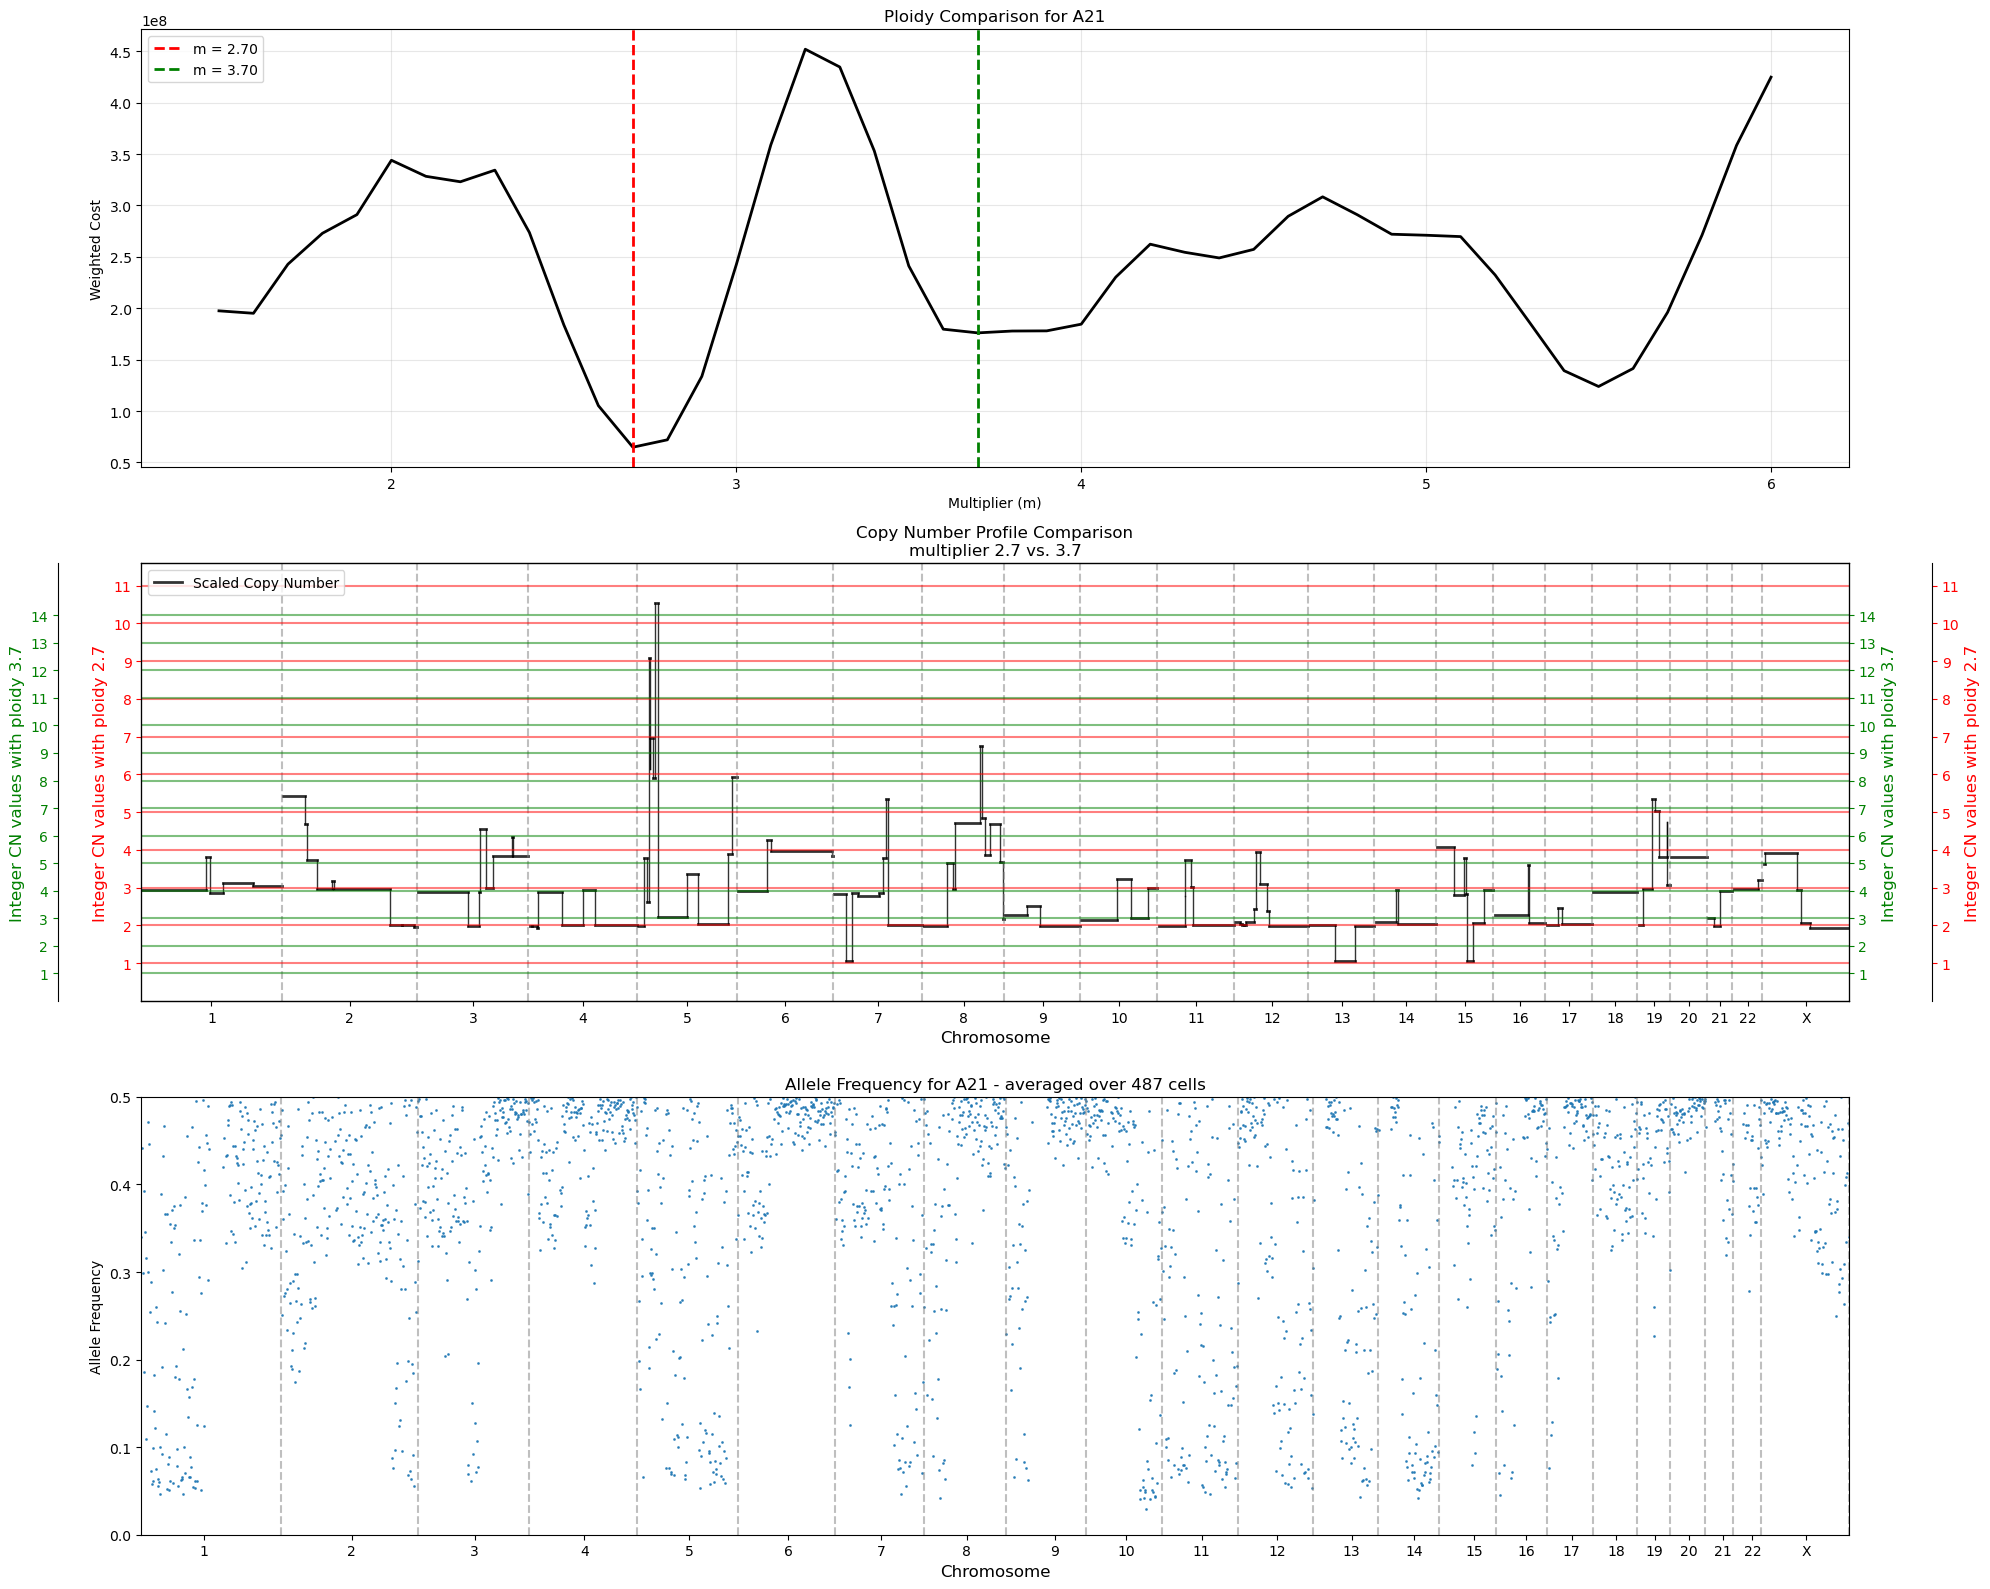

Compared 2.70 vs 3.70 for A21

Creating ploidy comparison for population: A221


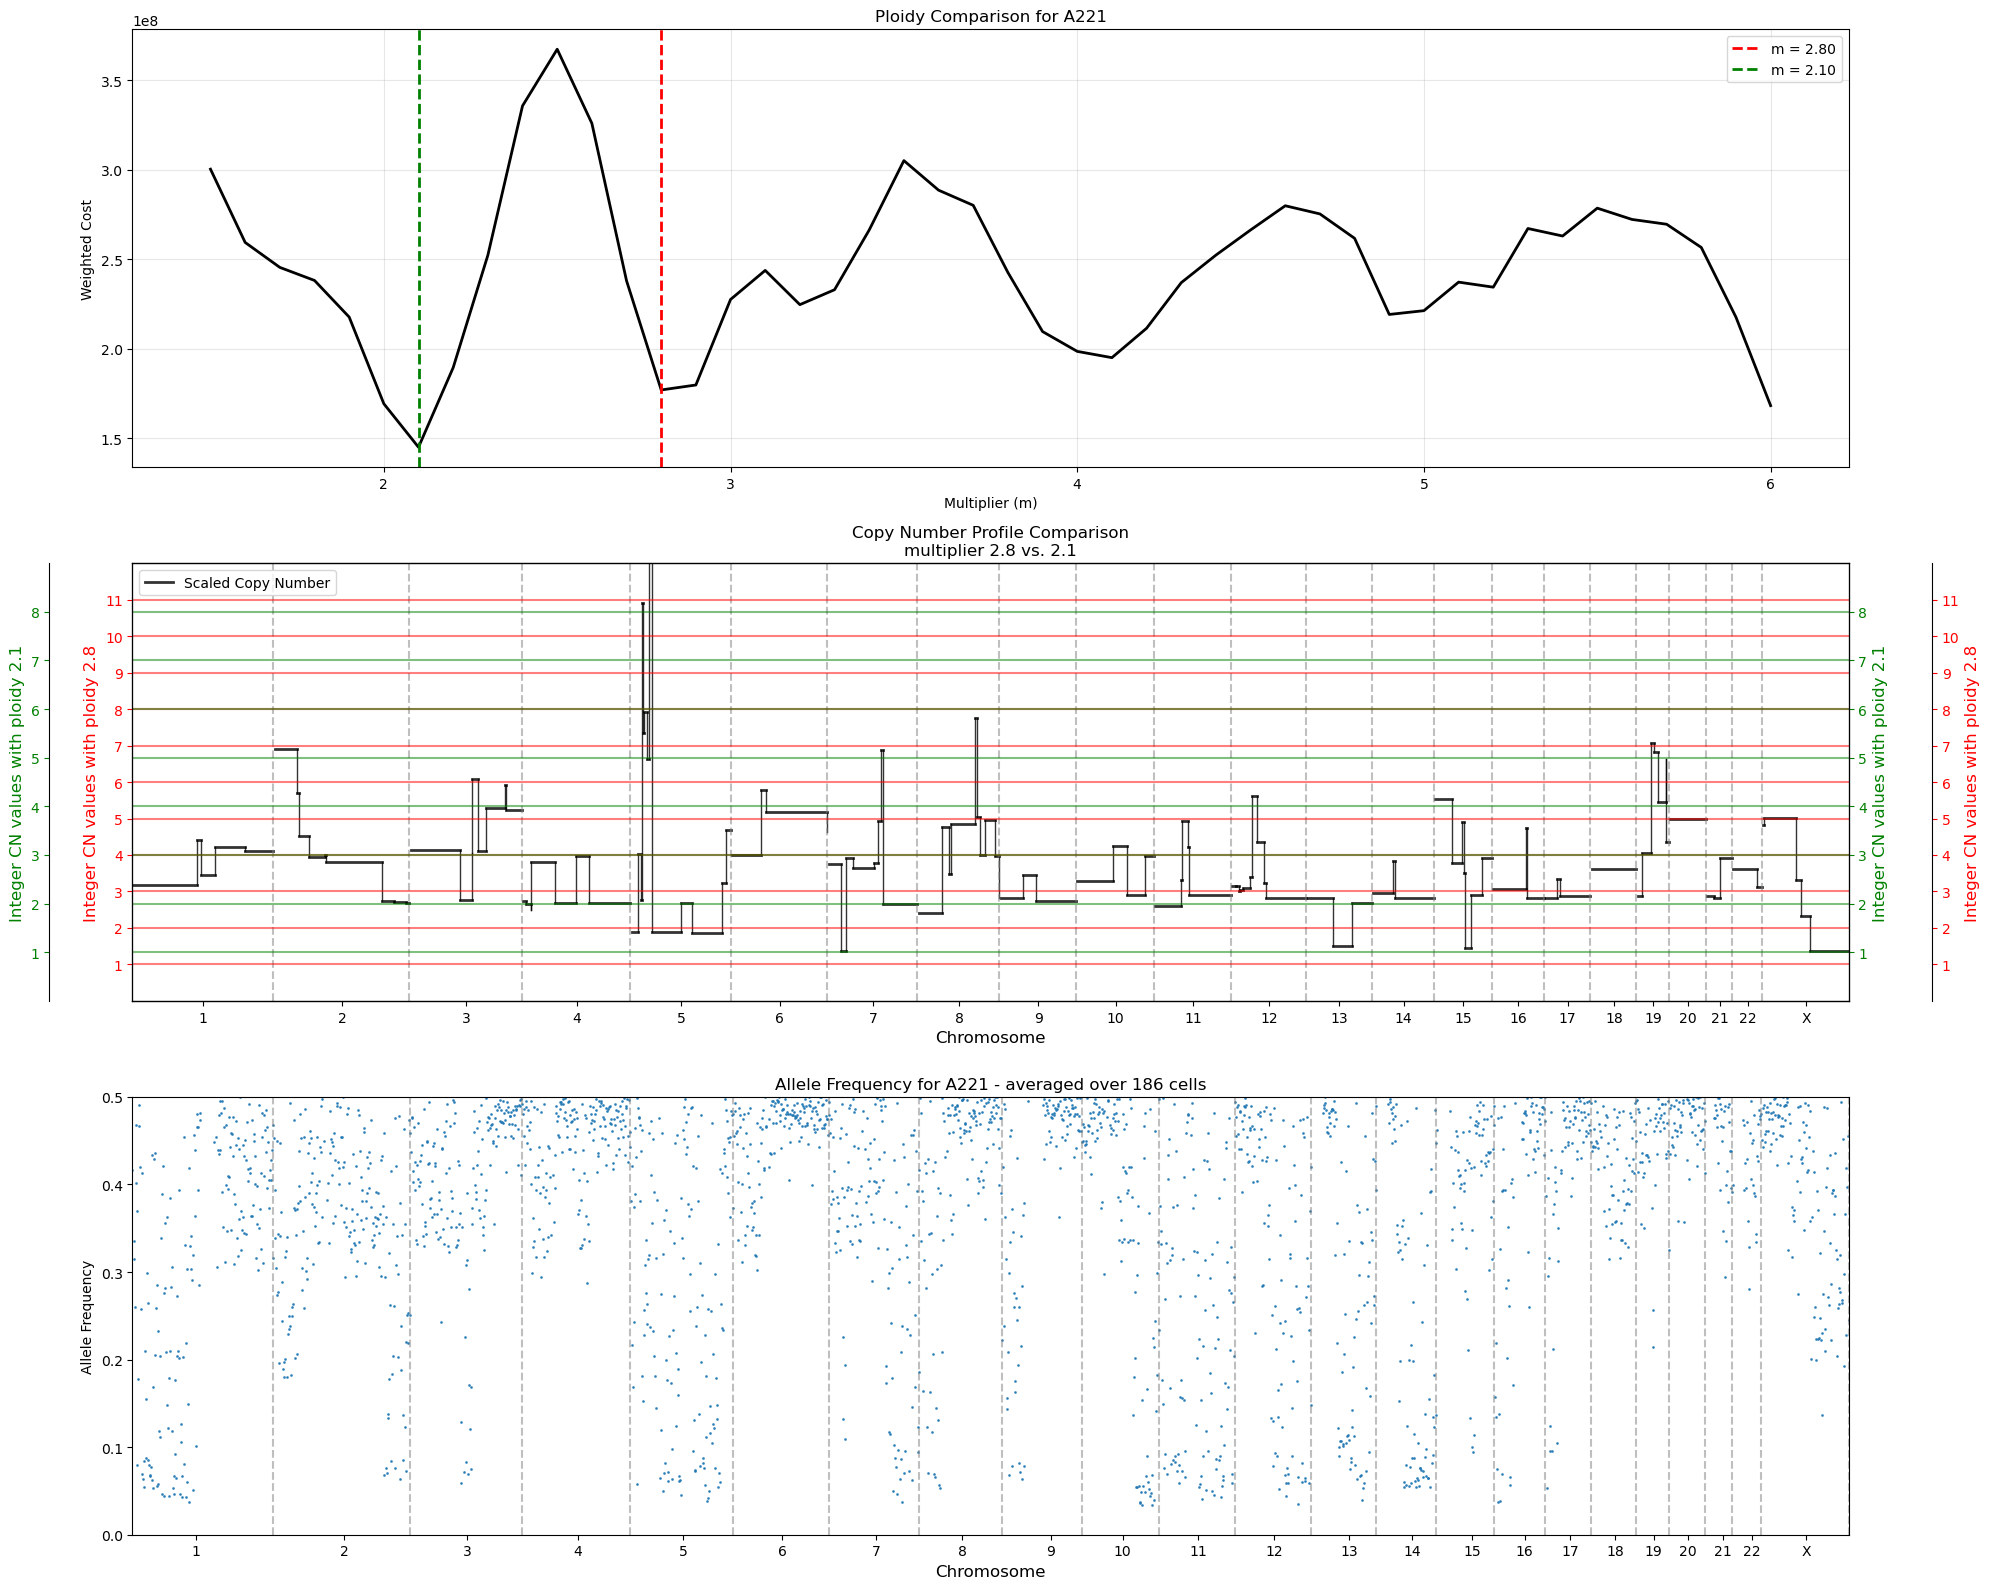

Compared 2.80 vs 2.10 for A221

Creating ploidy comparison for population: A2221


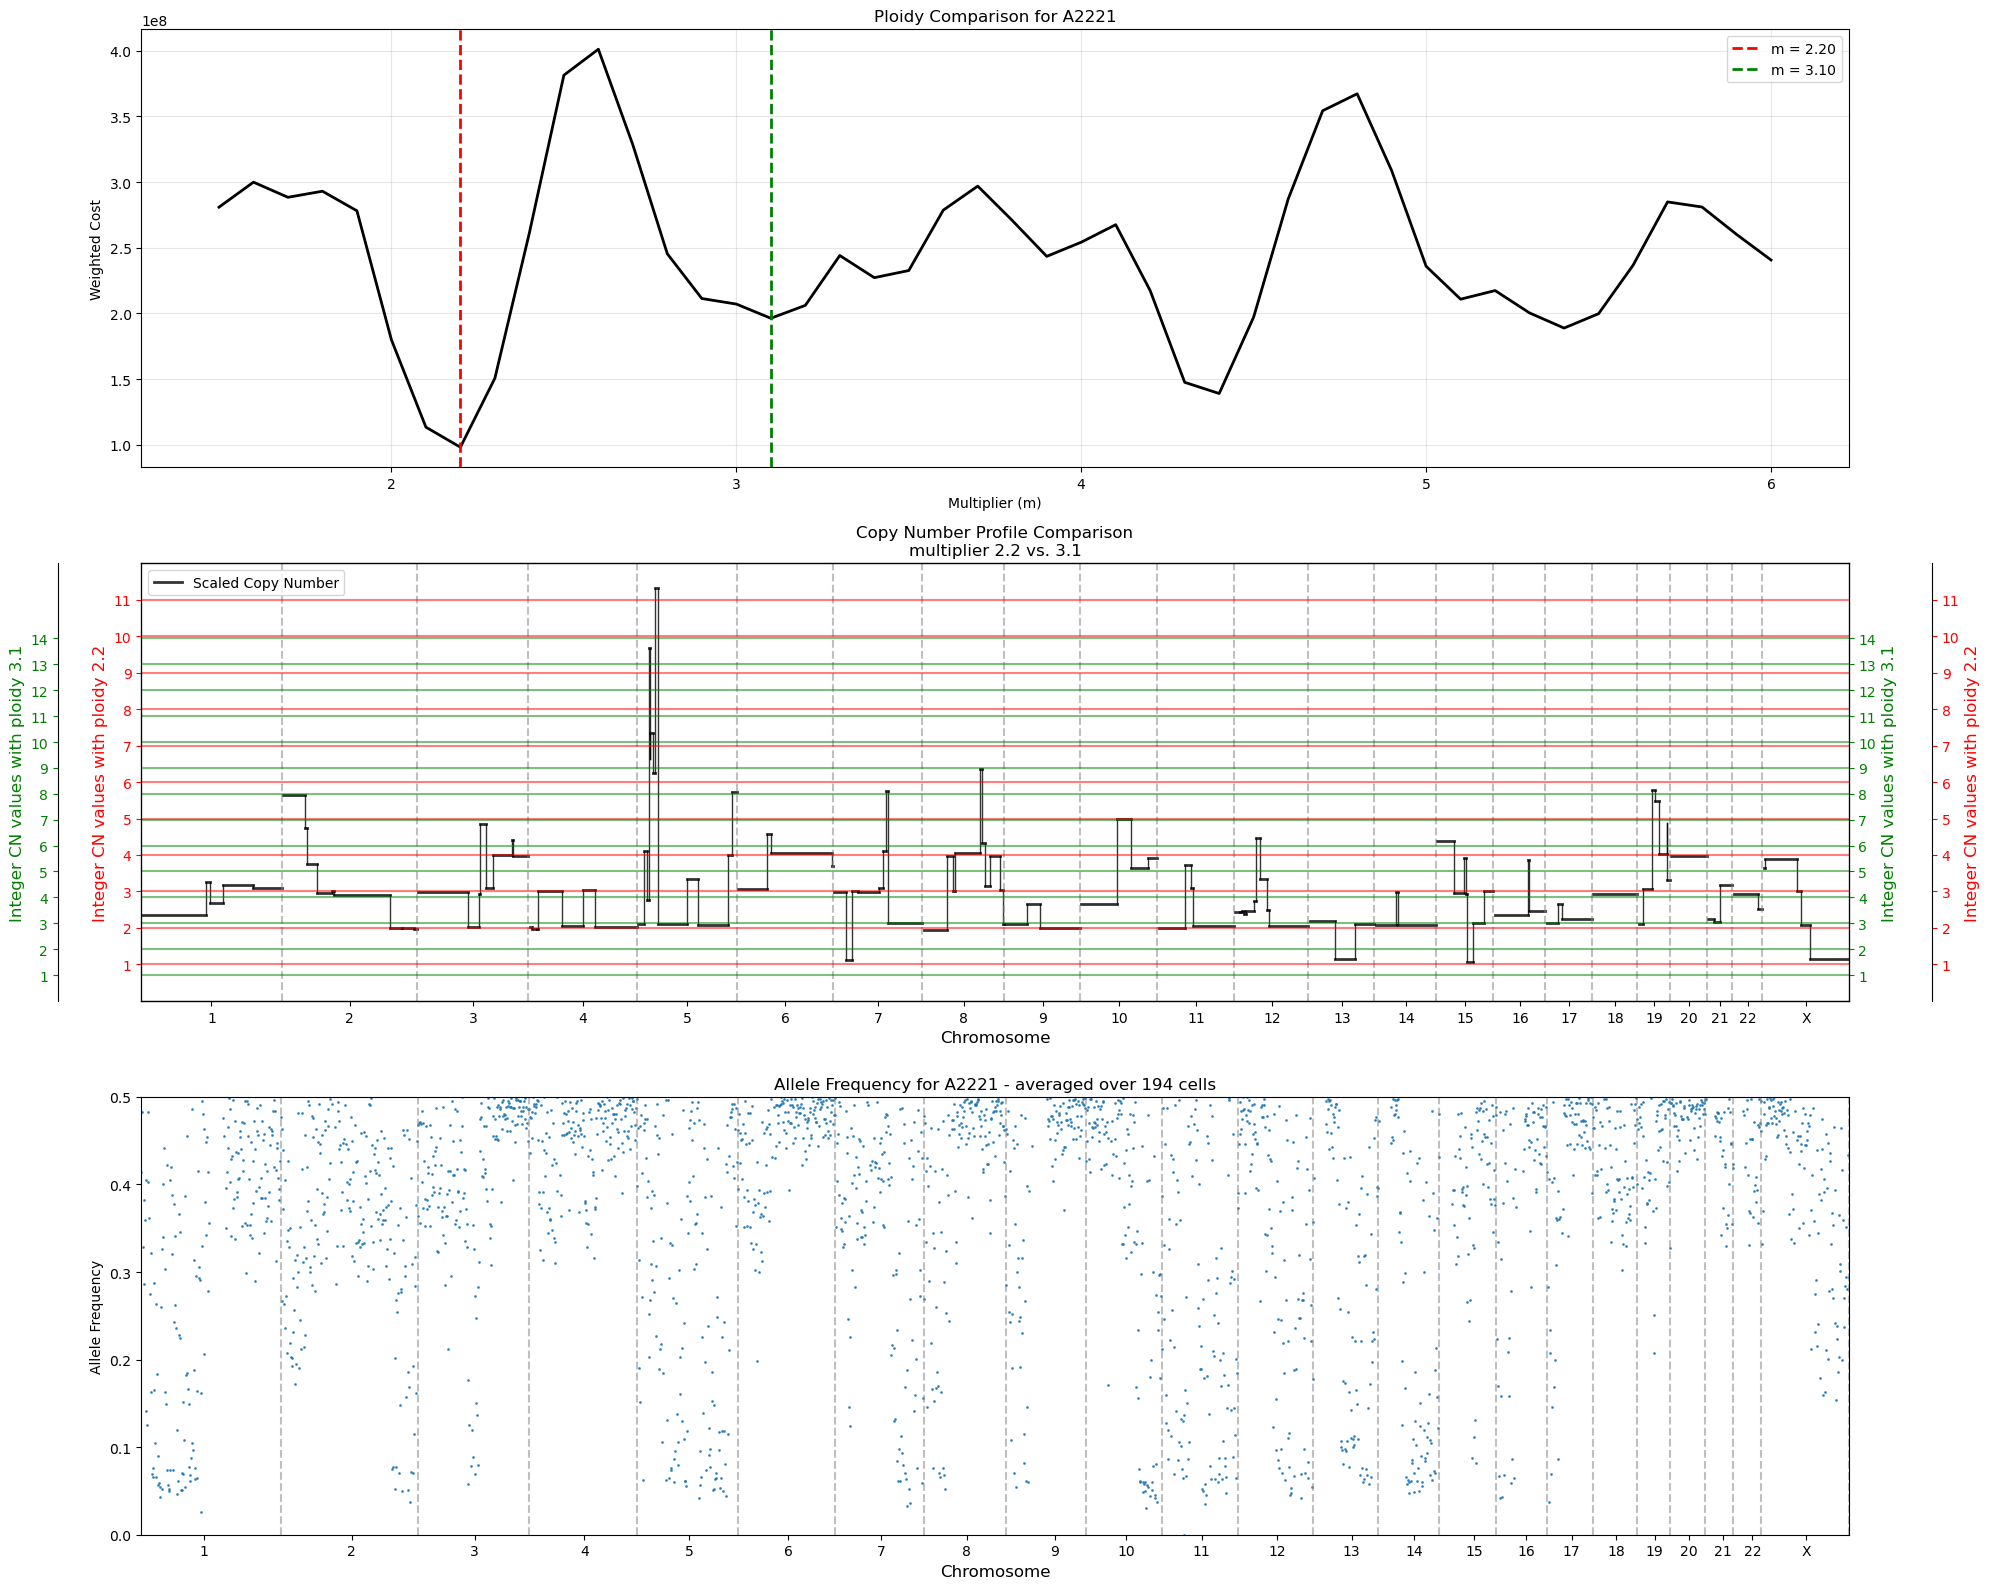

Compared 2.20 vs 3.10 for A2221

Creating ploidy comparison for population: A2222


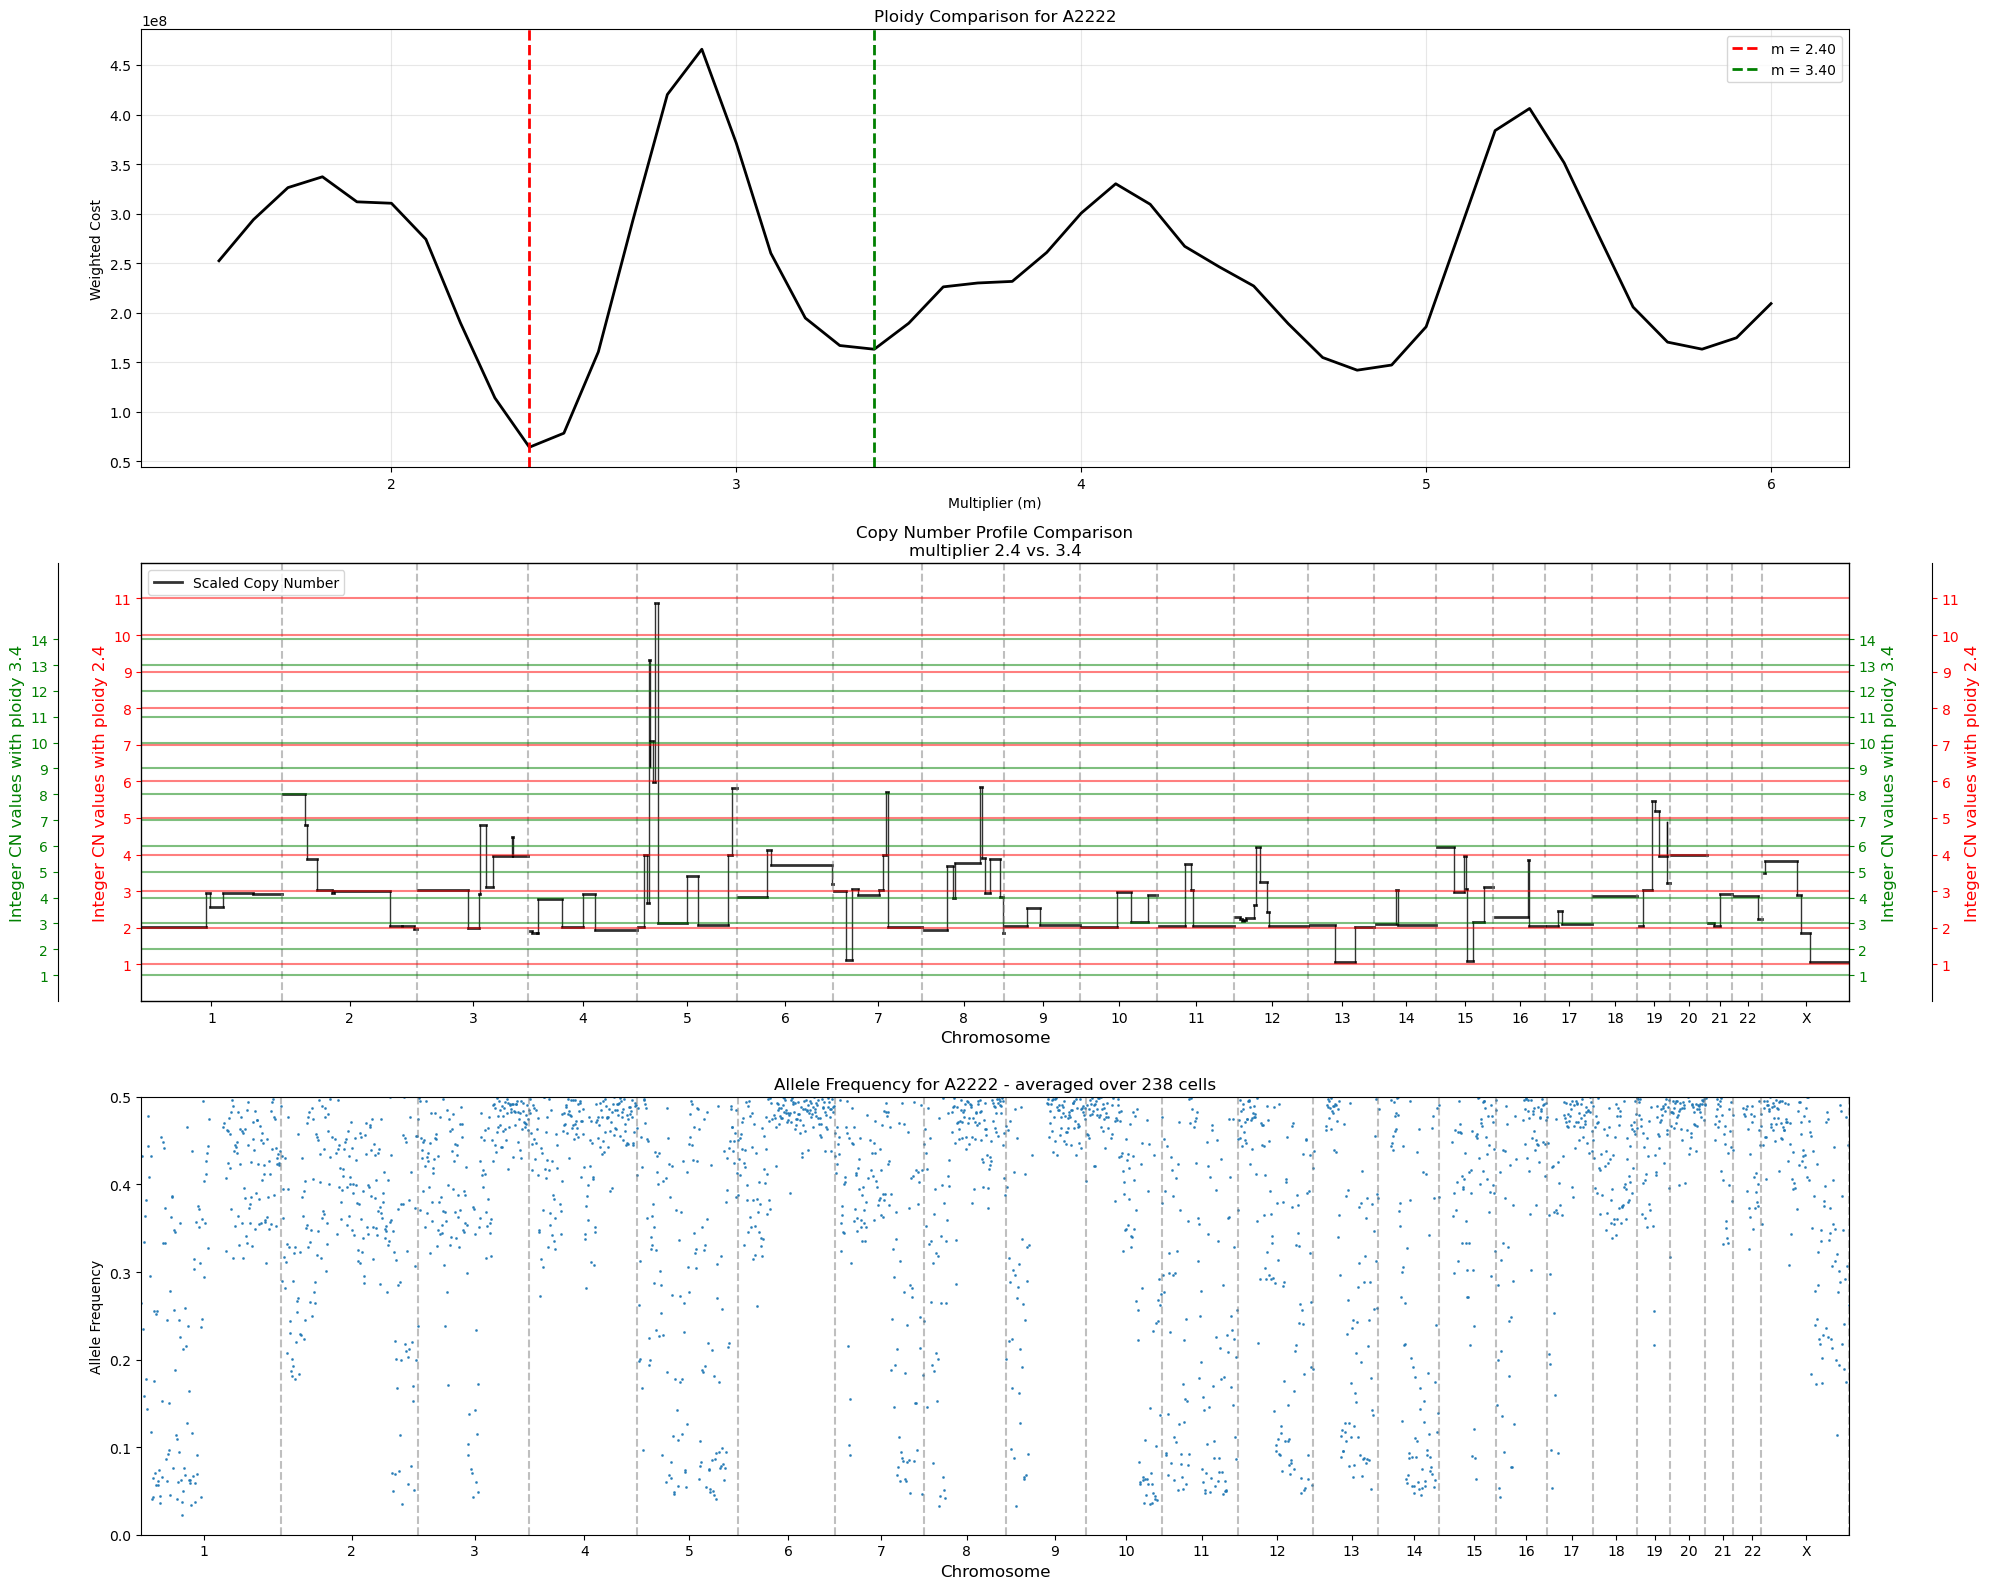

Compared 2.40 vs 3.40 for A2222


In [49]:
# Loop through all populations and create ploidy comparison plots
for pop_name in ploidy_results_A.keys():
    print(f"\n{'='*60}")
    print(f"Creating ploidy comparison for population: {pop_name}")
    
    results = ploidy_results_A[pop_name]
    local_minima = results['local_minima']
    optimal_m = results['optimal_multiplier']
    
    # Find the local minimum closest to ploidy 2 (that's not the global minimum)
    other_minima = [m for m, _ in local_minima if m != optimal_m]
    
    if other_minima:
        # Pick the one closest to 2.0
        second_best_m = min(other_minima, key=lambda x: abs(x - 2.0))
    else:
        print(f"Only one minimum found for {pop_name}, skipping comparison")
        continue
    
    plot_ploidy_comparison(
        results_df=profile_dfs_A[pop_name],
        cost_results=results['cost_results'],
        optimal_m=optimal_m,
        local_m=second_best_m,
        pop_col=f'{pop_name}_ratio',
        hap_count_df=hap_count_df,
        cells=A_dict[pop_name]['cells']
    )
    
    print(f"Compared {optimal_m:.2f} vs {second_best_m:.2f} for {pop_name}")


Creating ploidy comparison for population: A21


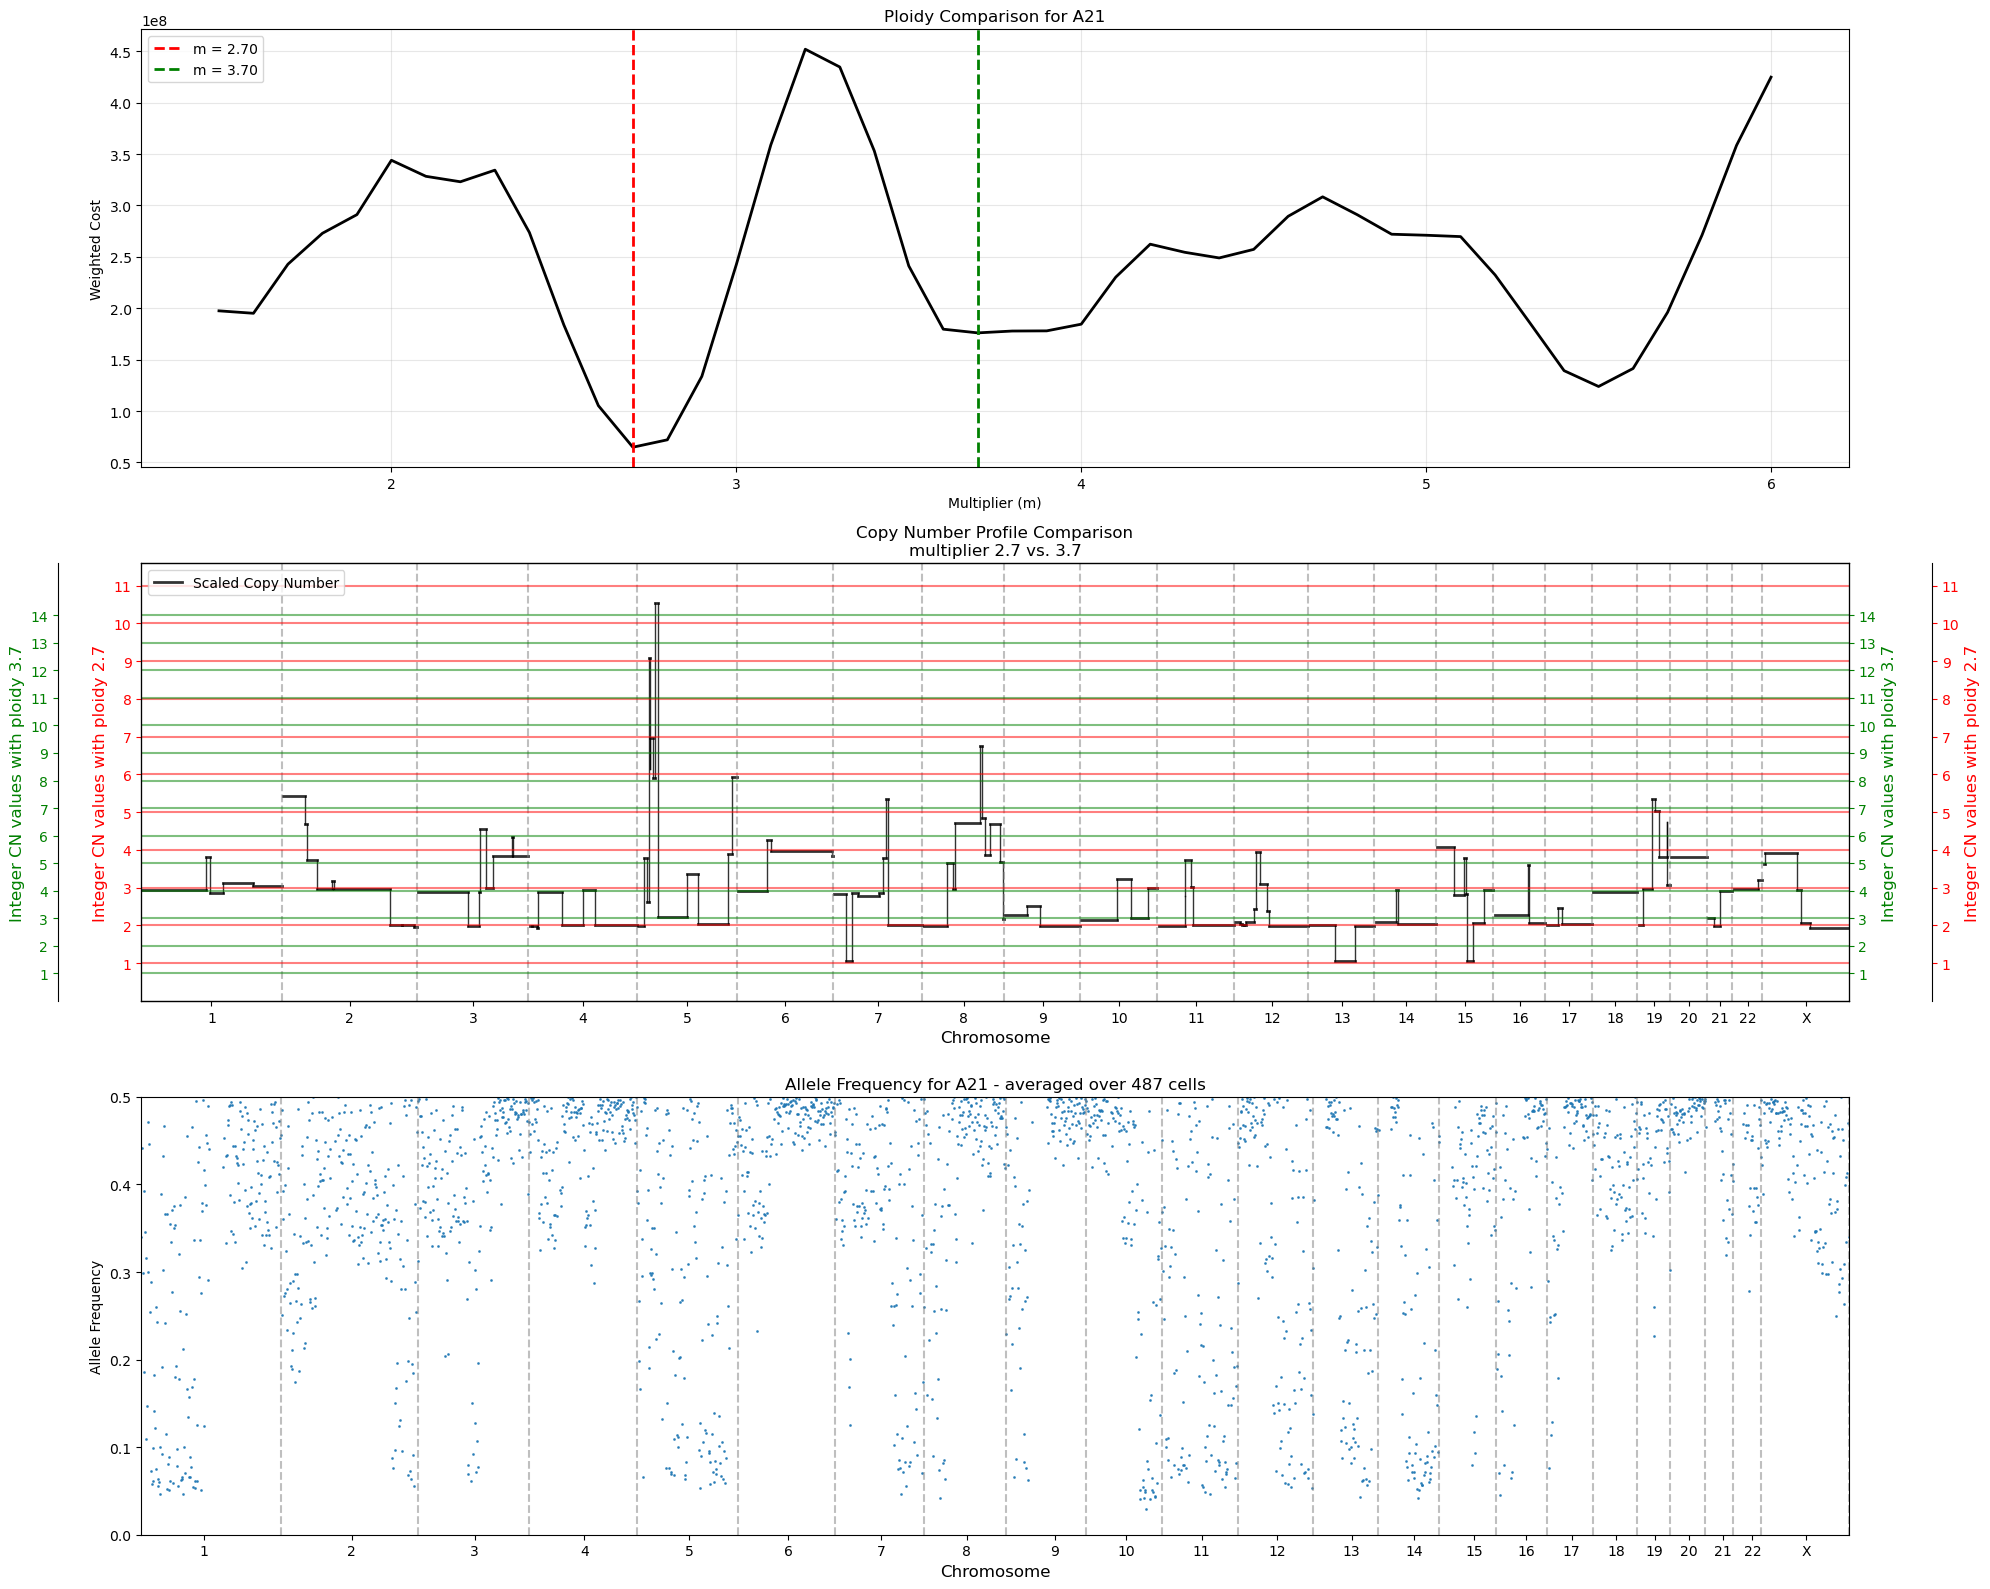

Compared 2.70 vs 3.70 for A21

Creating ploidy comparison for population: A221


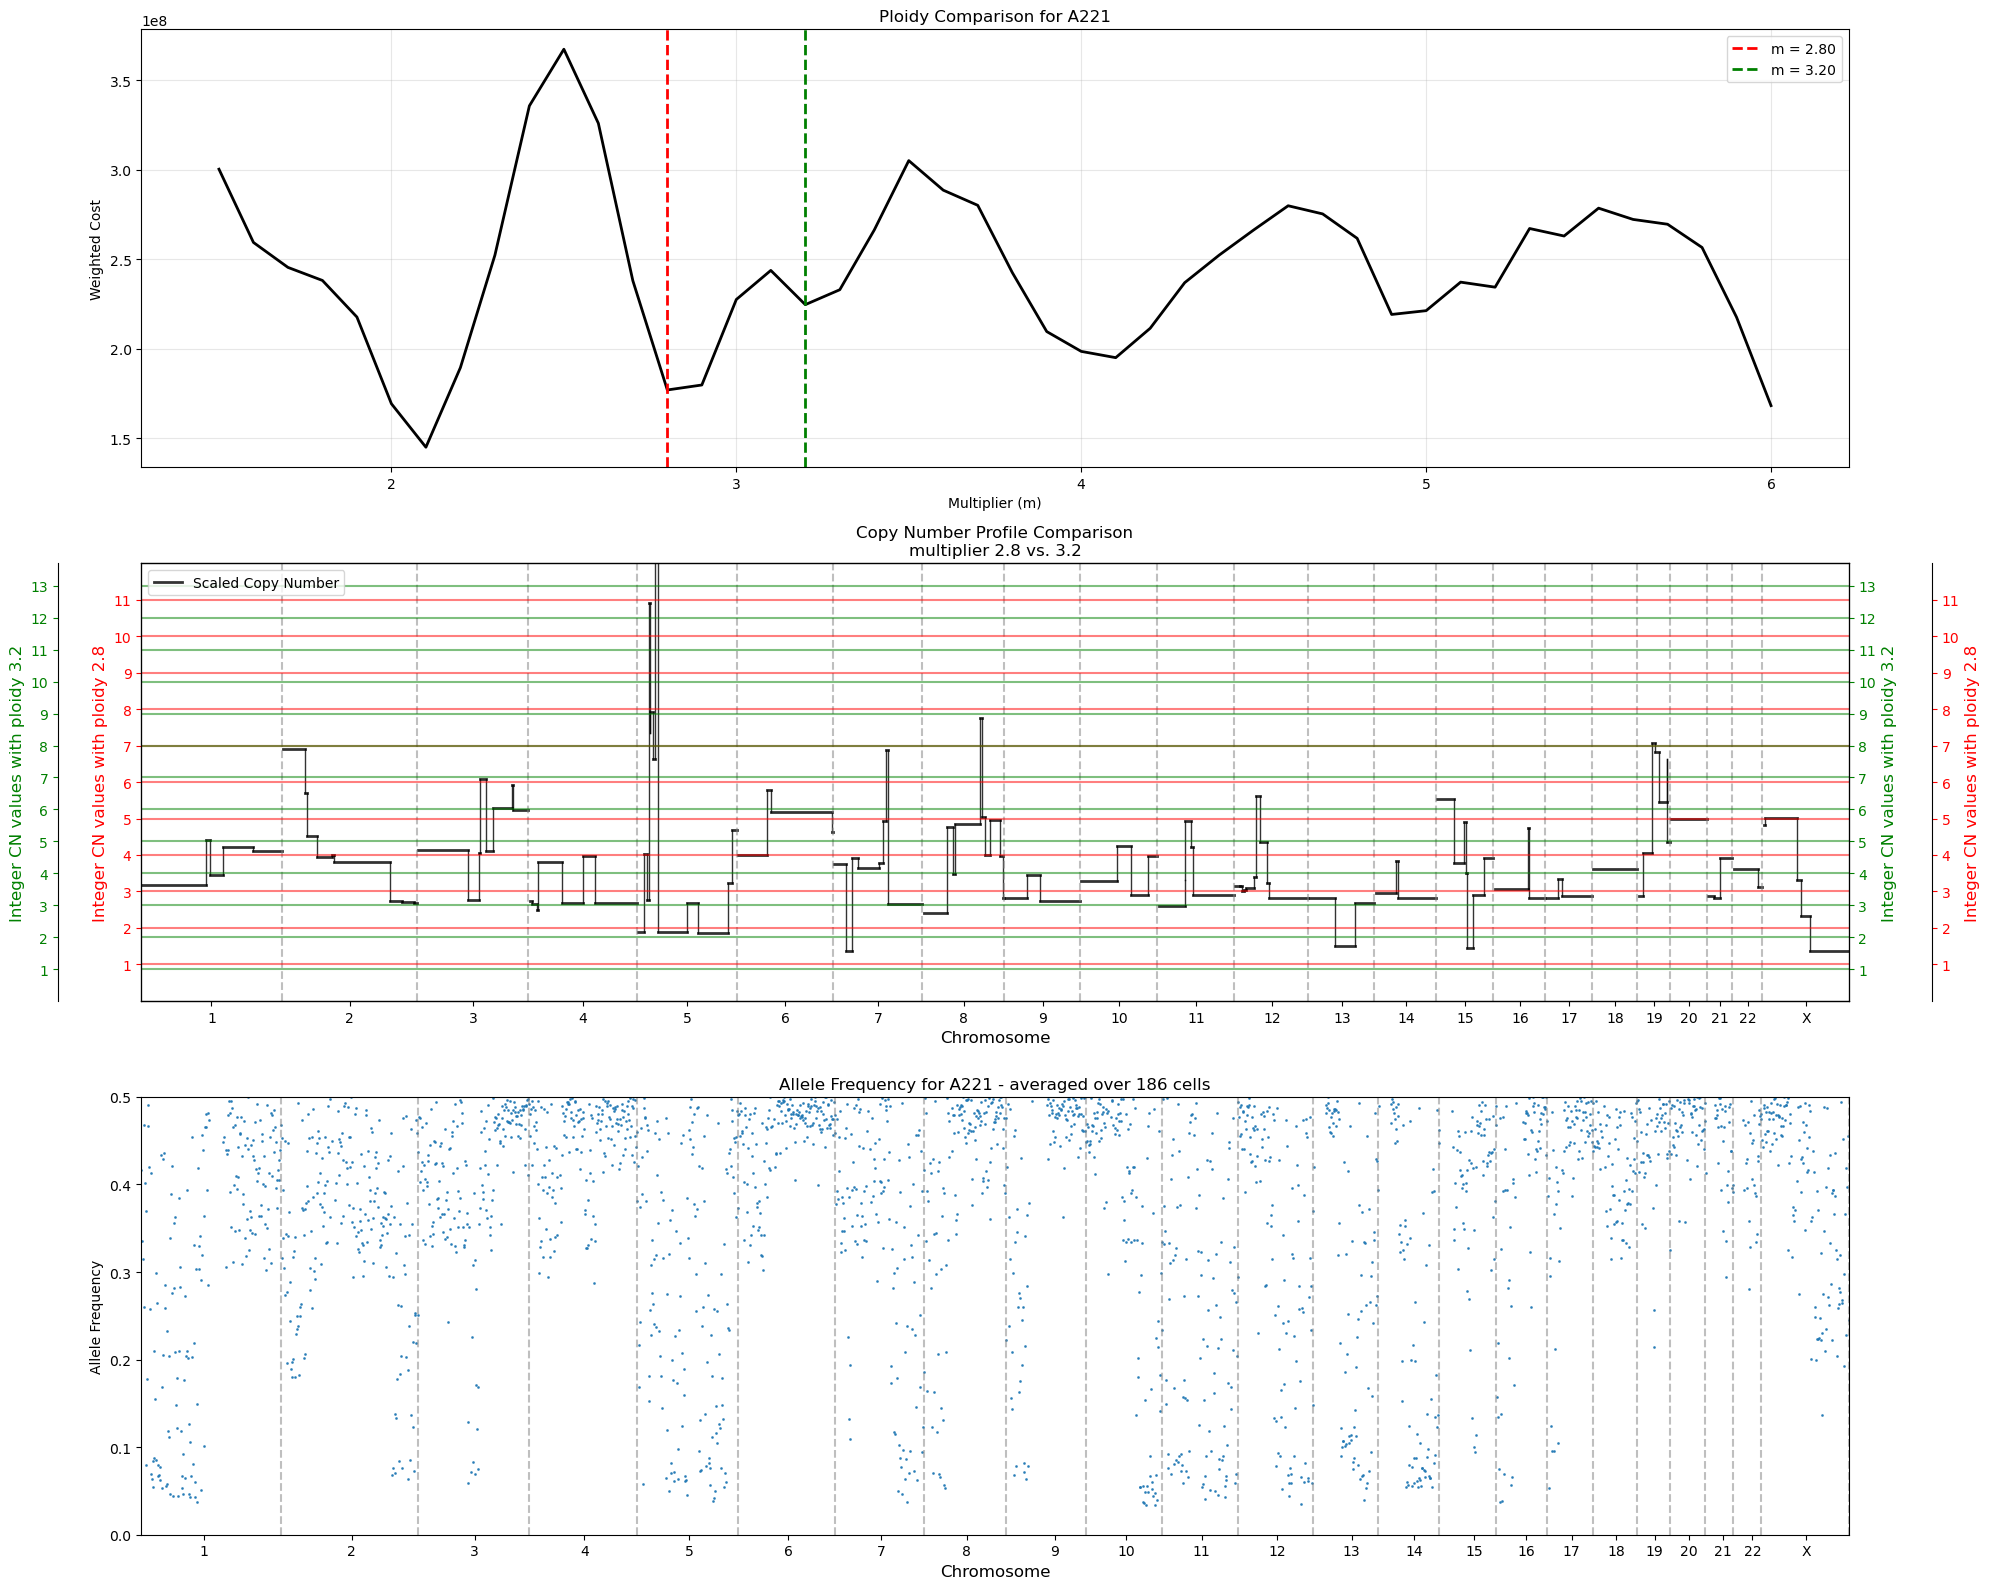

Compared 2.80 vs 3.20 for A221

Creating ploidy comparison for population: A2221


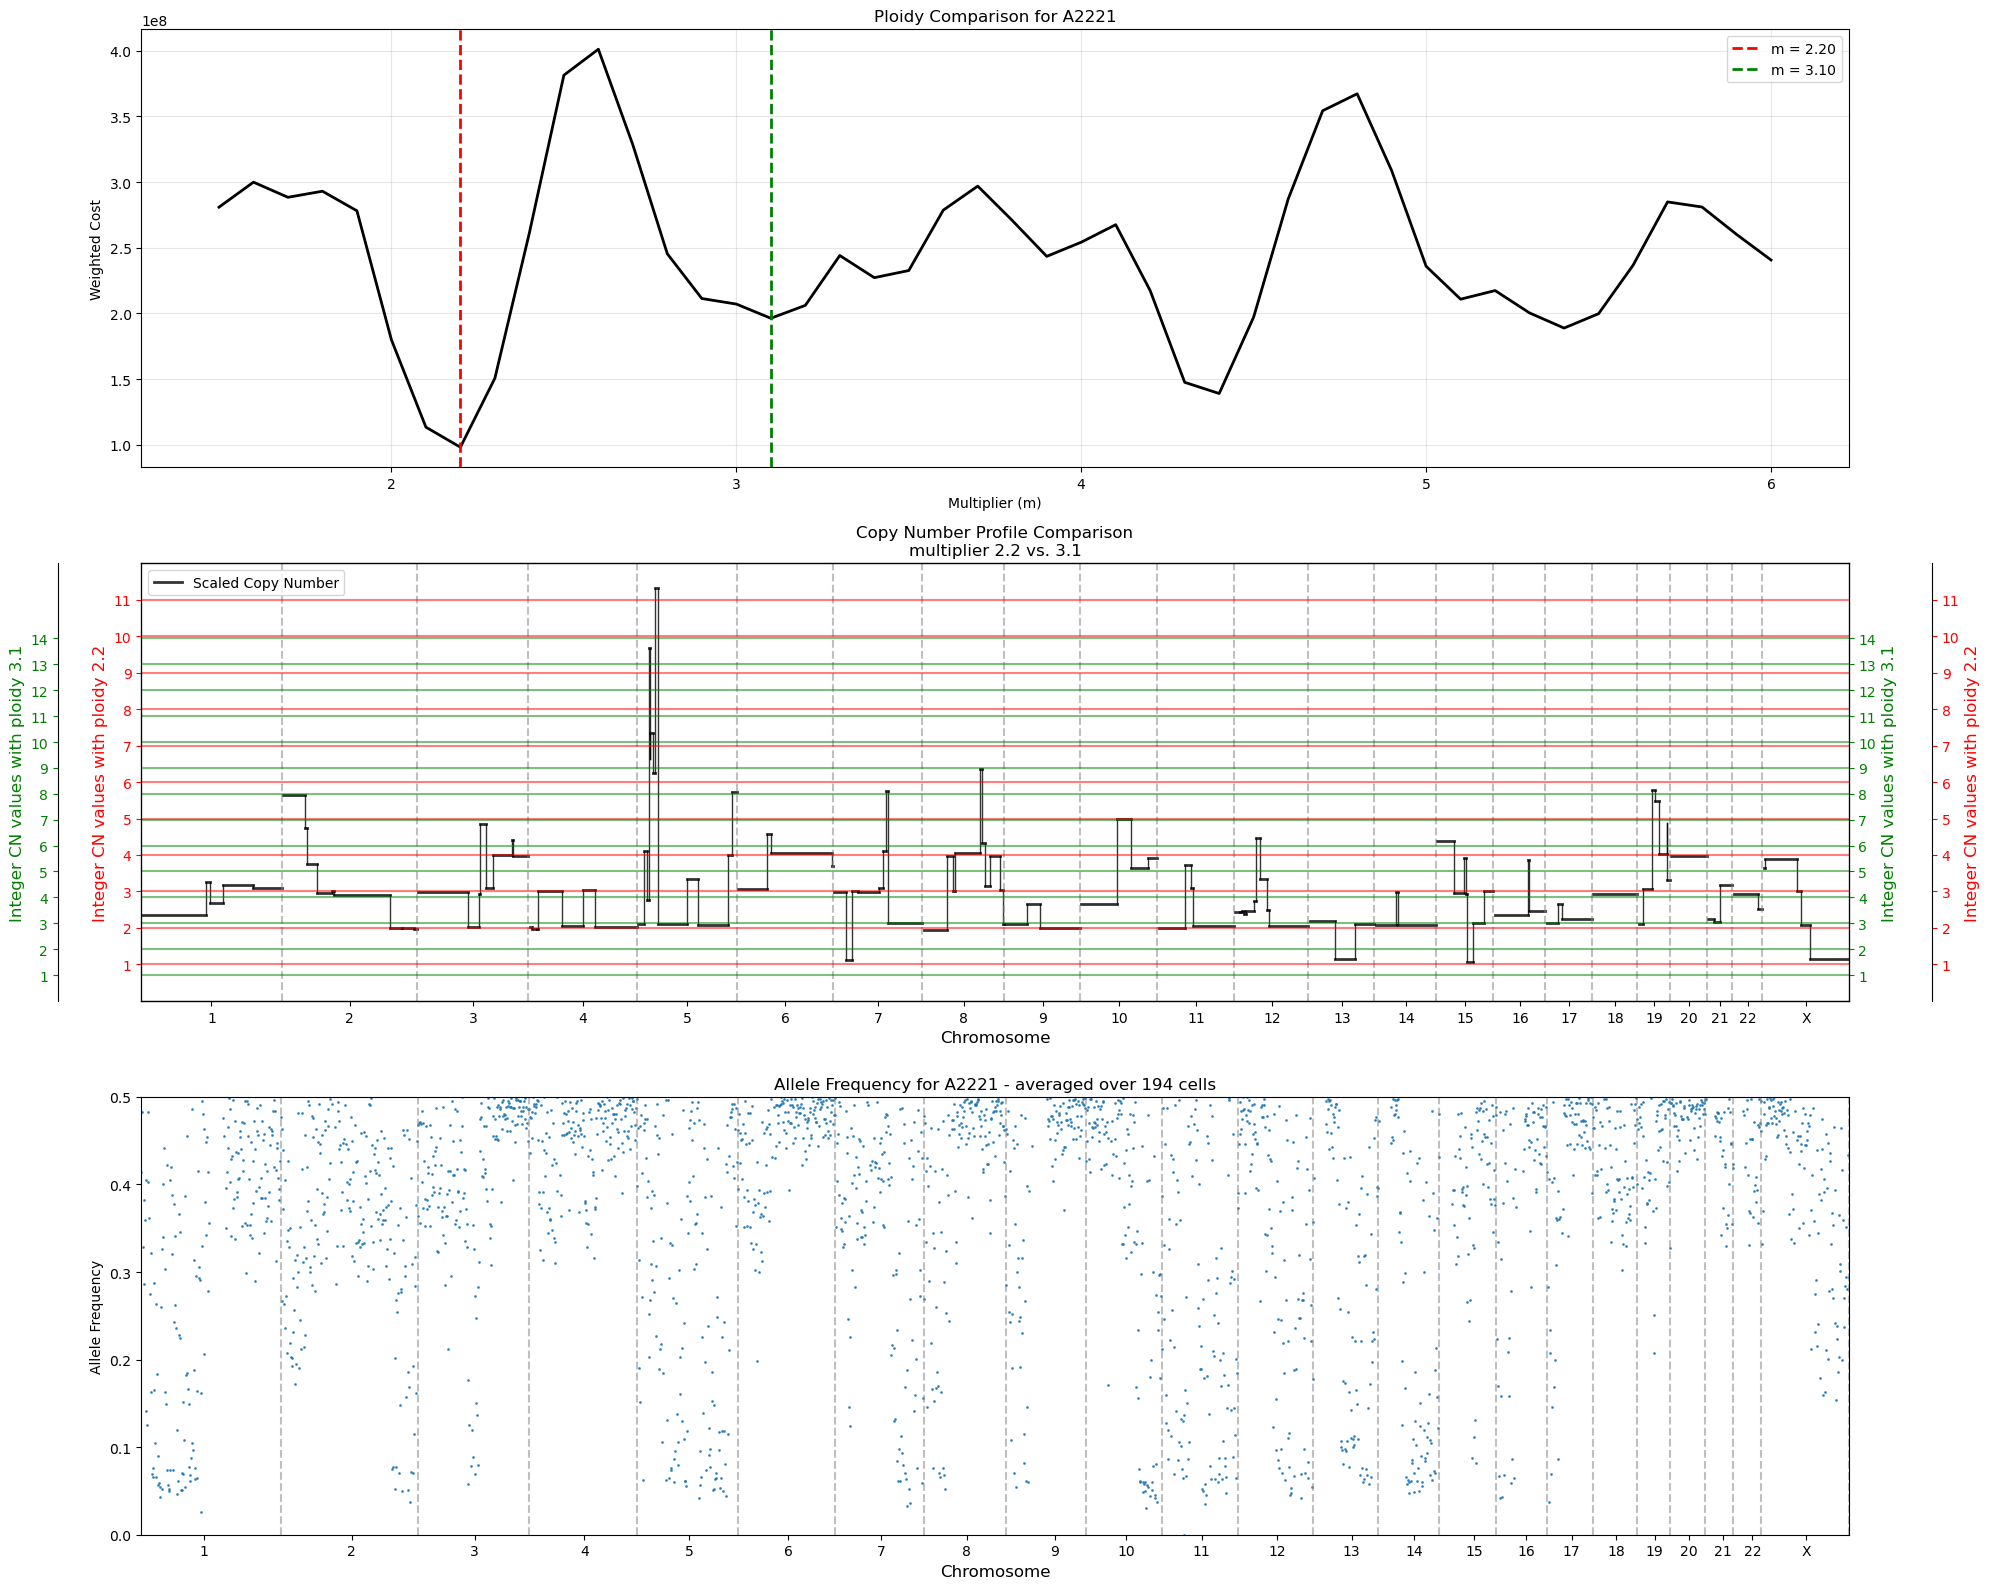

Compared 2.20 vs 3.10 for A2221

Creating ploidy comparison for population: A2222


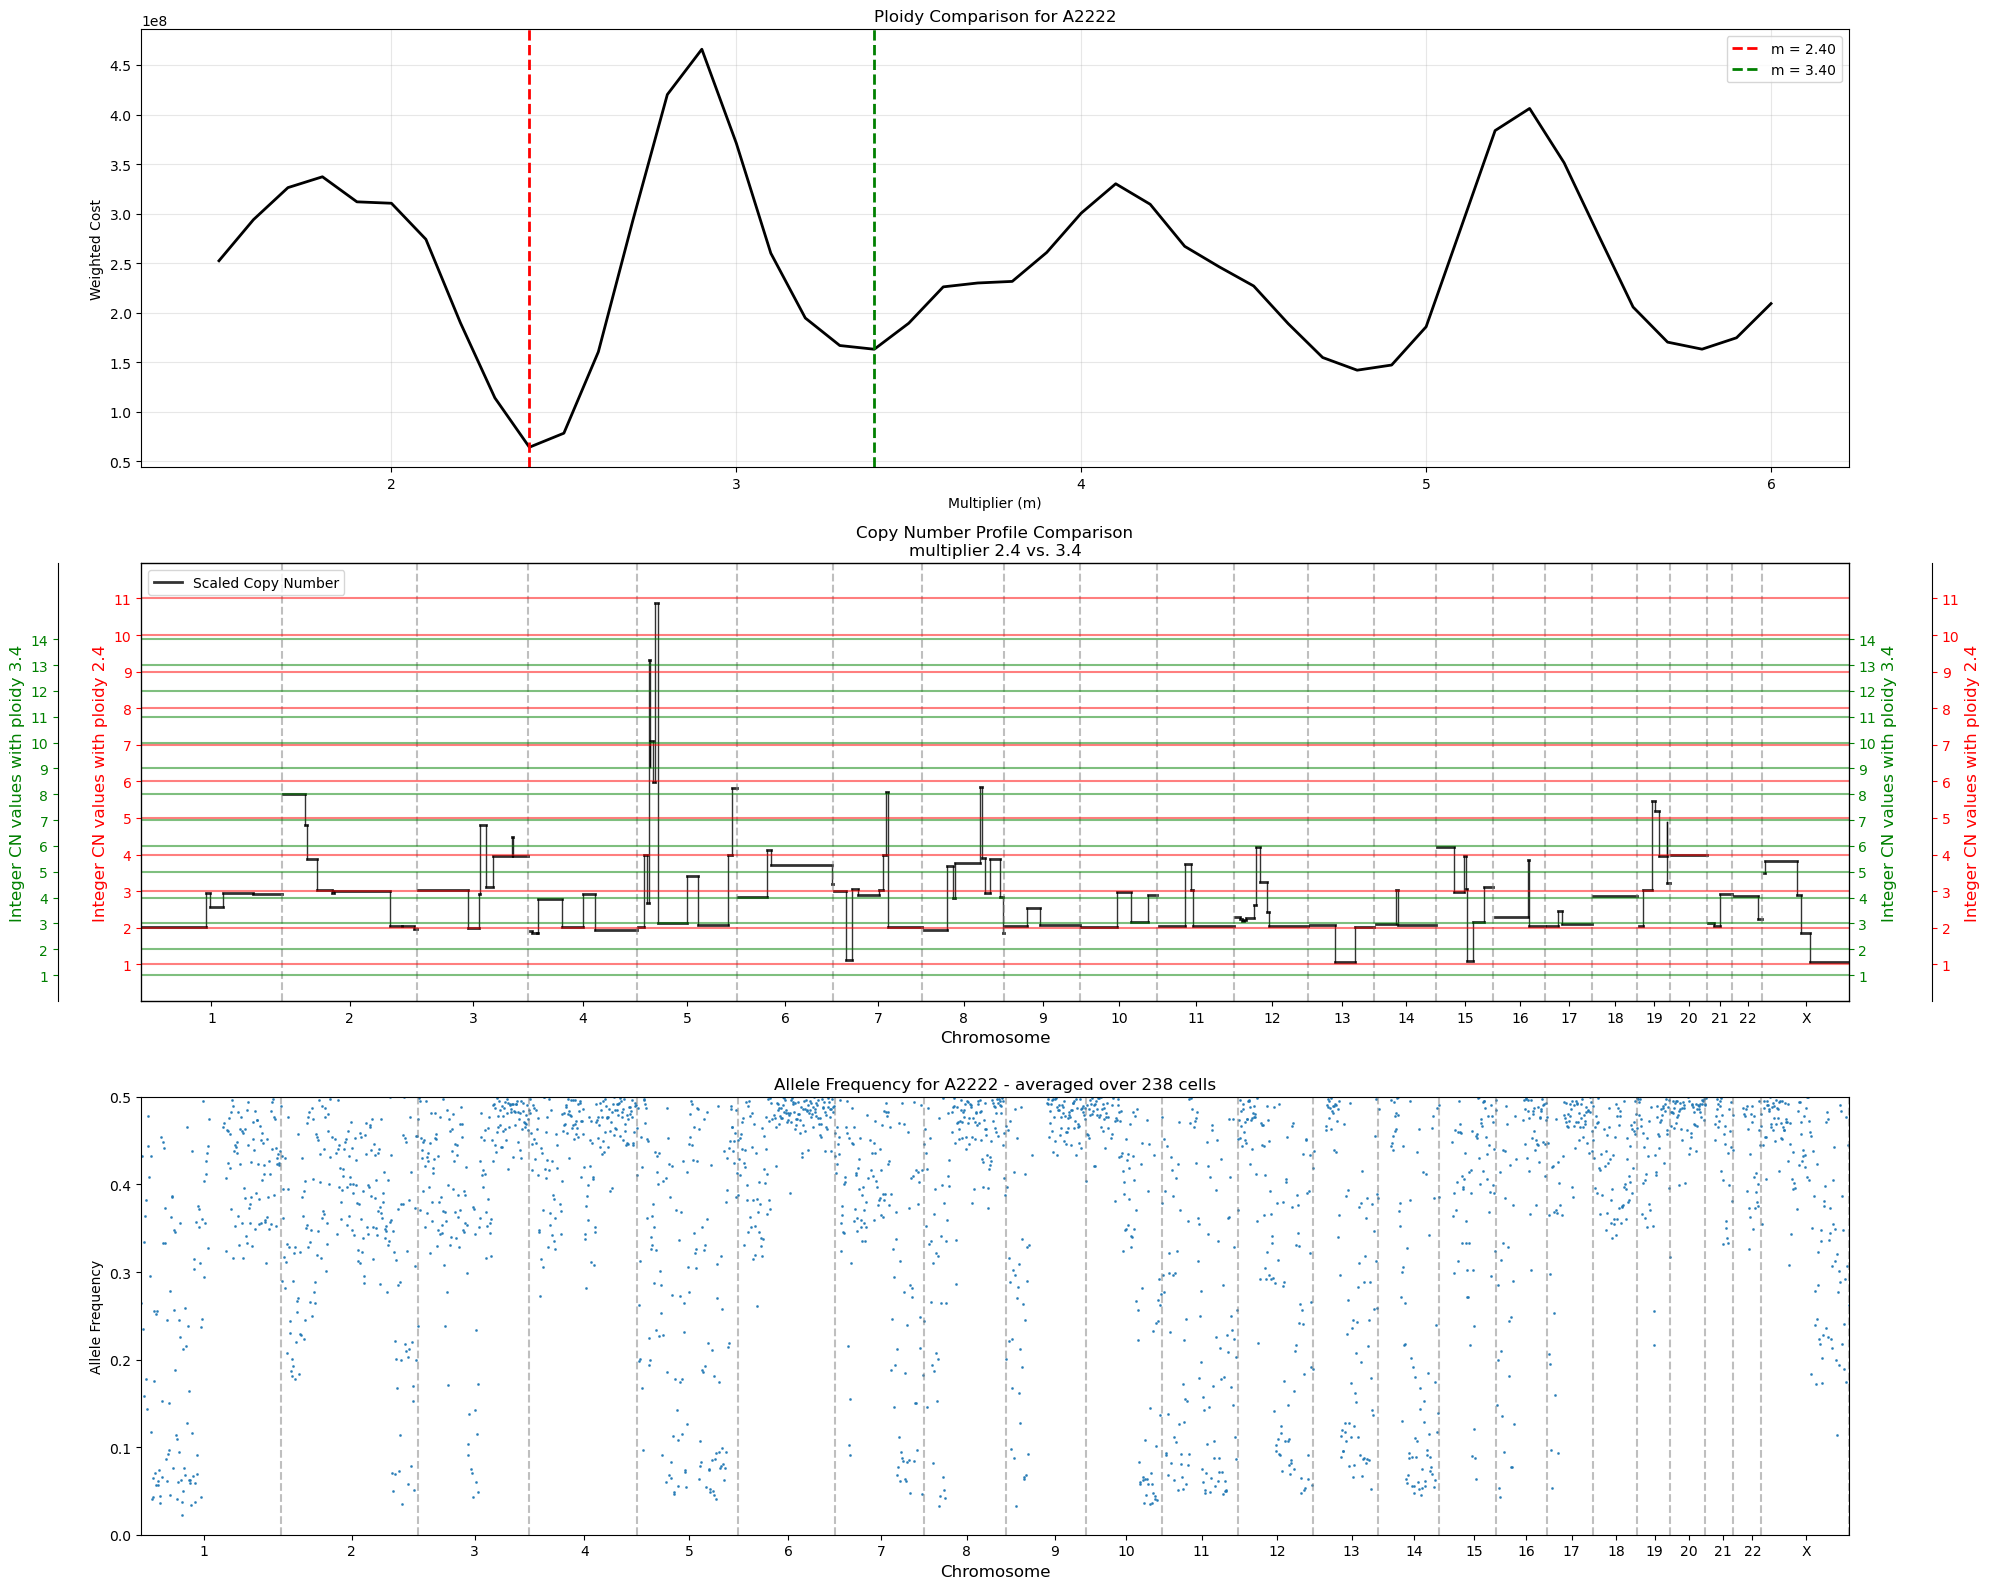

Compared 2.40 vs 3.40 for A2222


In [50]:
# Loop through all populations and create ploidy comparison plots
for pop_name in ploidy_results_A.keys():
    print(f"\n{'='*60}")
    print(f"Creating ploidy comparison for population: {pop_name}")
    
    results = ploidy_results_A[pop_name]
    local_minima = results['local_minima']
    optimal_m = results['optimal_multiplier']
    
    # Find the local minimum closest to the global minimum (excluding the global minimum itself)
    other_minima = [m for m, _ in local_minima if m != optimal_m]
    
    if other_minima:
        # Find the minimum distance to the global minimum
        min_distance = min(abs(m - optimal_m) for m in other_minima)
        # Get all minima at this minimum distance
        closest_minima = [m for m in other_minima if abs(m - optimal_m) == min_distance]
        # Pick the smaller one if there are ties
        second_best_m = min(closest_minima)
    else:
        print(f"Only one minimum found for {pop_name}, skipping comparison")
        continue
    
    plot_ploidy_comparison(
        results_df=profile_dfs_A[pop_name],
        cost_results=results['cost_results'],
        optimal_m=optimal_m,
        local_m=second_best_m,
        pop_col=f'{pop_name}_ratio',
        hap_count_df=hap_count_df,
        cells=A_dict[pop_name]['cells']
    )
    
    print(f"Compared {optimal_m:.2f} vs {second_best_m:.2f} for {pop_name}")

In [51]:
# # reorder A_dict based on new order from overlap_df index
# A_dict_reordered = {k: A_dict[k] for k in overlap_df.index}

In [52]:
# Add to your imports at the top:



In [53]:
# Create population summary table
summary_rows = []

for pop_name in A_dict.keys():
    # Get cells for this population
    pop_cells = A_dict[pop_name]['cells']
    num_cells = len(pop_cells)
    
        

    # Calculate average read count per cell for this population
    pop_data = all_data[pop_cells]
    avg_read_count = pop_data.sum().sum() / num_cells
    
    # Get relative counts (already computed in relative_counts_A)
    relative_count = relative_counts_A[pop_name].mean()

    if pop_name!= normal_A:
        results = ploidy_results_A[pop_name]
        local_minima = results['local_minima']
        target_m = 2 * relative_count
        #pick two best minima
        optimal_m = min(dict(local_minima).keys(), key=lambda x: abs(x - target_m))
        second_best_m = min([m for m, _ in local_minima if m != optimal_m], key=lambda x: abs(x - target_m))
    
    # Get relative ploidy from ploidy_results_A (if it exists, otherwise it's the normal so use 1.0)
    if pop_name in ploidy_results_A:
        relative_ploidy = optimal_m
    else:
        relative_ploidy = 2.0  # Normal population
        second_best_m = 2.0
    
    # Add (normal) label if this is the normal population
    display_name = f"{pop_name} (normal)" if pop_name == normal_A else pop_name
    
    summary_rows.append({
        'pop_name': display_name,
        'num_cells': num_cells,
        'avg_read_count_per_cell': avg_read_count,
        'relative_counts': relative_count,
        'best_ploidy': relative_ploidy,
        'second_best' : second_best_m
    })

# Create DataFrame
population_summary_table = pd.DataFrame(summary_rows)


#display it nicely
population_summary_table

,pop_name,num_cells,avg_read_count_per_cell,relative_counts,best_ploidy,second_best
0,A1 (normal),263,68602.695817,1.000000,2.0,2.0
1,A21,487,71058.700205,1.035800,2.7,3.7
2,A221,186,87257.505376,1.271925,2.8,2.1
3,A2221,194,88831.510309,1.294869,2.2,3.1
4,A2222,238,77586.184874,1.130950,2.4,3.4


In [54]:
population_summary_table.to_csv(f"../data/{tumor}/{tumor}_ploidy_summary_table_A.txt", sep="\t", index=False)

=== Creating Copy Number Heatmaps ===
Processing 124 segments using vectorized operations...
Normal factor computed
Data normalized by normal factor
Data normalized by cell means
Ploidy multipliers applied
Copy number matrix created successfully!
Heatmap A matrix dimensions: 124 segments × 1368 cells
Expanding heatmap from 124 segments to 5256 rows...

Chromosome representation in heatmap:
chr1: 438 rows, 245,459,747 bp total
chr2: 421 rows, 234,695,583 bp total
chr3: 346 rows, 193,355,005 bp total
chr4: 334 rows, 187,016,981 bp total
chr5: 311 rows, 173,502,285 bp total
chr6: 295 rows, 165,412,919 bp total
chr7: 276 rows, 154,658,822 bp total
chr8: 252 rows, 140,707,474 bp total
chr9: 234 rows, 131,151,738 bp total
chr10: 238 rows, 133,218,101 bp total
chr11: 236 rows, 132,149,408 bp total
chr12: 228 rows, 127,978,359 bp total
chr13: 202 rows, 113,350,205 bp total
chr14: 189 rows, 105,554,000 bp total
chr15: 176 rows, 98,373,534 bp total
chr16: 158 rows, 88,486,226 bp total
chr17: 142

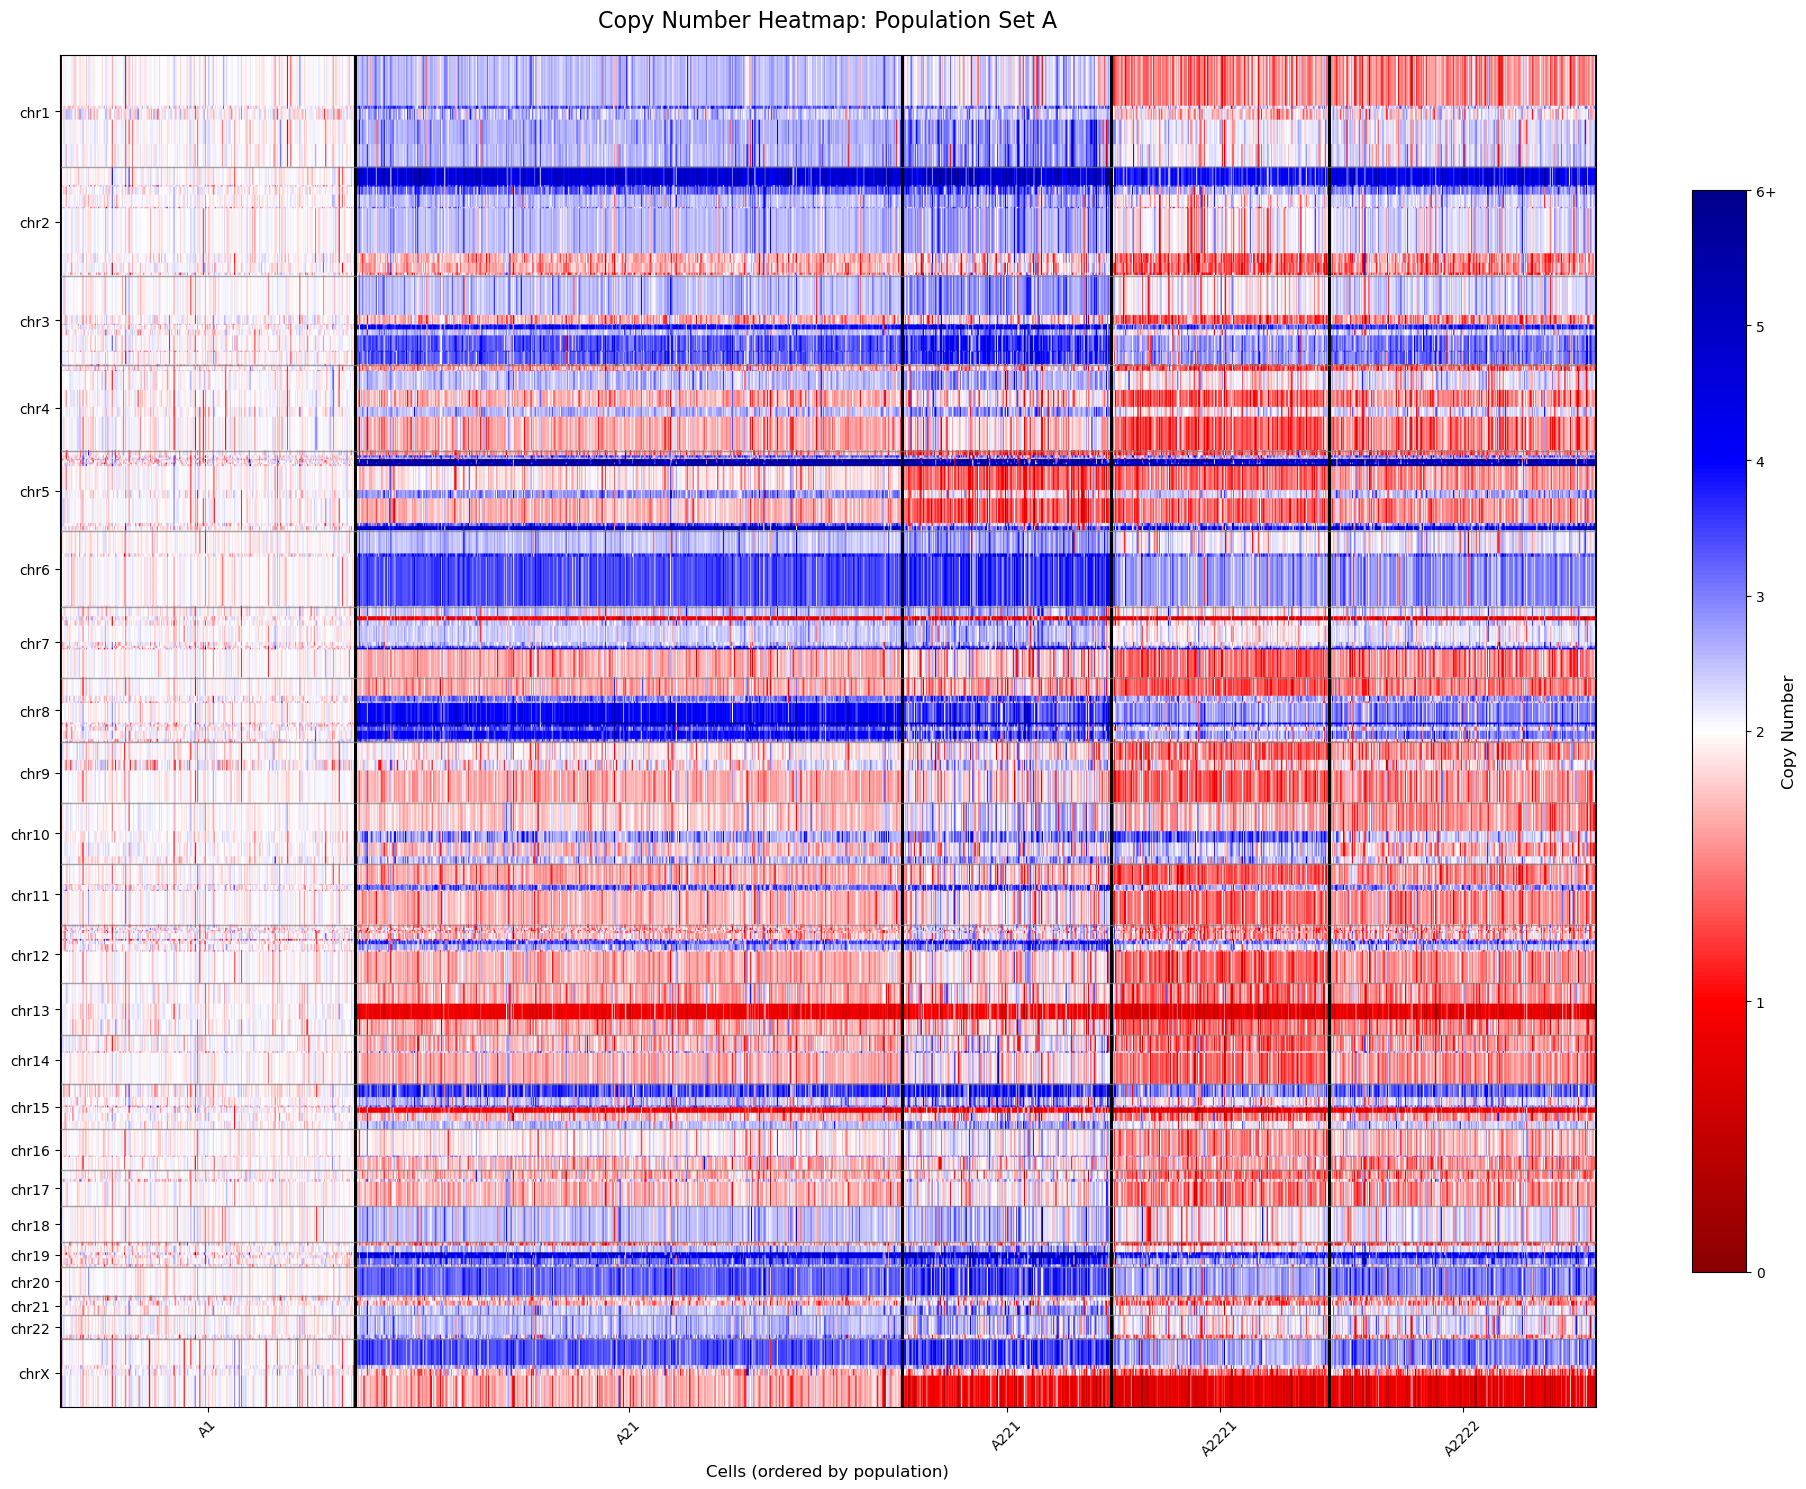

In [55]:
from copy_number import create_copy_number_matrix_fast
from visualization import plot_copy_number_heatmap, plot_overlap_matrix_figure

# Then you can use these functions in your analysis:

# Create heatmaps for both population sets
print("=== Creating Copy Number Heatmaps ===")

# For Population Set A
heatmap_df_A, cell_mapping_A, boundaries_A, segment_info_A = create_copy_number_matrix_fast(
    all_data, 
    A_dict, 
    ratios_A, 
    {f"{pop}_ratio": ploidy_results_A[pop]['optimal_multiplier'] for pop in ploidy_results_A.keys()}, 
    normal_A
)

print(f"Heatmap A matrix dimensions: {heatmap_df_A.shape[0]} segments × {heatmap_df_A.shape[1]} cells")

plot_copy_number_heatmap(
    heatmap_df_A, 
    boundaries_A, 
    segment_info_A,
    title="Copy Number Heatmap: Population Set A"
)

In [56]:
if tumor == "t57":
    pop_name = "A1221"    
    results = ploidy_results_A[pop_name]
    local_minima = results['local_minima']
    optimal_m = results['optimal_multiplier']

    
    # Find the local minimum closest to the global minimum (excluding the global minimum itself)
    other_minima = [m for m, _ in local_minima if m != optimal_m]
    
    if other_minima:
        # Find the minimum distance to the global minimum
        min_distance = min(abs(m - optimal_m) for m in other_minima)
        # Get all minima at this minimum distance
        closest_minima = [m for m in other_minima if abs(m - optimal_m) == min_distance]
        # Pick the smaller one if there are ties
        second_best_m = min(closest_minima)

    temp_df = profile_dfs_A[pop_name].copy()
    temp_df["A1221_ratio_scaled"] = (temp_df["A1221_ratio_scaled"]/optimal_m)*second_best_m

    plot_ploidy_comparison(
        results_df=temp_df,
        cost_results=results['cost_results'],
        optimal_m=second_best_m,
        local_m= optimal_m,
        pop_col=f'{pop_name}_ratio',
        hap_count_df=hap_count_df,
        cells=A_dict[pop_name]['cells']
    )
    
    
    
    